In [2]:
# ===== Experiment identity: the ONLY lines that differ between notebooks 01-05 =====
EXPERIMENT_ID = '03_Green_Channel'
PREPROCESSING_METHOD = 'green_channel'

# ===== Frozen experimental protocol: identical in all five notebooks =====
PROTOCOL = dict(
    seed_main=42, ablation_seeds=[42, 43, 44],
    split_fractions=dict(train=0.70, val=0.15, test=0.15), split_seed=2026,
    cache_size=256, image_size=224, crop_threshold=10,
    near_duplicate_hamming=8, near_duplicate_ncc=0.90, duplicate_policy='keep_one_per_consistent_cluster',
    conflicting_duplicate_policy='exclude_cluster',
    architectures=['EfficientNetB0', 'ResNet50', 'DenseNet121', 'ConvNeXtTiny'],
    pretrained_weights='torchvision IMAGENET1K_V1',
    attention='cbam', cbam_reduction=16, cbam_spatial_kernel=7, head_dropout=0.2,
    batch_size=32, max_epochs=30, warmup_frozen_epochs=2,
    lr_head=1e-3, lr_backbone=1e-4, weight_decay=1e-4, optimizer='AdamW', lr_schedule='cosine_per_epoch',
    early_stopping_patience=6, min_delta=1e-4, grad_clip_norm=1.0, mixed_precision=True,
    class_weighting='inverse_frequency_normalised_CE',
    primary_metric='qwk', secondary_metric='macro_f1',
    augmentation=dict(rrc_scale=[0.85, 1.0], rrc_ratio=[0.95, 1.05], hflip=0.5,
                      rotation=15, brightness=0.1, contrast=0.1),
    n_bootstrap=2000, n_permutations=5000, alpha=0.05,
)

RUN_OPTIONS = dict(
    force_retrain=False,          # True = ignore finished runs and retrain
    run_ablation=True,            # extra seeds + no-attention ablation on the selected architecture
    keep_last_checkpoint=False,   # delete the large resume checkpoint once a run finishes
    num_workers=2,
)
DATASET_OVERRIDES = {}  # e.g. {'label_csv': '.../train.csv', 'id_col': 'id_code', 'label_col': 'diagnosis', 'image_dir': '.../train_images'}

import os, sys, json, hashlib
SMOKE_TEST = os.environ.get('DR_SMOKE_TEST') == '1'   # tiny offline pipeline check ONLY; never set in Colab
if SMOKE_TEST:
    PROTOCOL.update(cache_size=96, image_size=64, max_epochs=3, warmup_frozen_epochs=1,
                    early_stopping_patience=2, batch_size=16, ablation_seeds=[42, 43],
                    n_bootstrap=200, n_permutations=200)
    RUN_OPTIONS['num_workers'] = 0
    print('!!! SMOKE TEST MODE: tiny settings, results are meaningless !!!')

PROTOCOL_HASH = hashlib.sha256(json.dumps(PROTOCOL, sort_keys=True).encode()).hexdigest()[:12]
print(f'Experiment: {EXPERIMENT_ID} | preprocessing: {PREPROCESSING_METHOD} | protocol hash: {PROTOCOL_HASH}')

Experiment: 03_Green_Channel | preprocessing: green_channel | protocol hash: 7432ebb9823f


In [3]:
import importlib, subprocess
for pkg, mod in [('PyWavelets', 'pywt'), ('ImageHash', 'imagehash')]:
    if importlib.util.find_spec(mod) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)

import random, time, shutil, platform, math, copy, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import cv2, pywt, imagehash, sklearn, scipy
from PIL import Image
import torch, torch.nn as nn, torchvision
from torch.utils.data import Dataset, DataLoader
from IPython.display import display, Markdown

warnings.filterwarnings('ignore', category=UserWarning, module='torchvision')
pd.set_option('display.width', 200, 'display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = bool(PROTOCOL['mixed_precision'] and DEVICE.type == 'cuda')
if DEVICE.type != 'cuda':
    print('WARNING: no GPU detected. Training will be extremely slow on CPU. '
          'In Colab choose Runtime > Change runtime type > GPU.')

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(PROTOCOL['seed_main'])

ENV = dict(python=platform.python_version(), platform=platform.platform(), torch=torch.__version__,
           torchvision=torchvision.__version__, numpy=np.__version__, pandas=pd.__version__,
           opencv=cv2.__version__, pywavelets=pywt.__version__, scikit_learn=sklearn.__version__,
           scipy=scipy.__version__, imagehash=imagehash.__version__, matplotlib=matplotlib.__version__,
           cuda=torch.version.cuda, cudnn=torch.backends.cudnn.version(),
           device=str(DEVICE), gpu=torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else None,
           mixed_precision=USE_AMP, cpu_count=os.cpu_count())
for k, v in ENV.items():
    print(f'{k:>14}: {v}')

def to_jsonable(o):
    if isinstance(o, dict): return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_jsonable(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return None if np.isnan(o) else float(o)
    if isinstance(o, float) and math.isnan(o): return None
    if isinstance(o, np.ndarray): return to_jsonable(o.tolist())
    if isinstance(o, Path): return str(o)
    return o

def save_json(obj, path):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    Path(path).write_text(json.dumps(to_jsonable(obj), indent=2))

        python: 3.13.15
      platform: Linux-6.6.122+-x86_64-with-glibc2.39
         torch: 2.11.0+cu130
   torchvision: 0.26.0+cu130
         numpy: 2.1.3
        pandas: 2.2.3
        opencv: 4.14.0
    pywavelets: 1.8.0
  scikit_learn: 1.6.1
         scipy: 1.16.3
     imagehash: 4.3.2
    matplotlib: 3.10.0
          cuda: 13.0
         cudnn: 92700
        device: cuda
           gpu: Tesla T4
mixed_precision: True
     cpu_count: 2


In [4]:
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

dataset_path = os.environ.get('DR_DATASET_ROOT', '/content/drive/MyDrive/Colab Notebooks')
OUTPUT_ROOT = Path(os.environ.get('DR_OUTPUT_ROOT', '/content/drive/MyDrive/DR_Grading_Research'))
LOCAL_CACHE = Path(os.environ.get('DR_LOCAL_CACHE', '/content/dr_local_cache'))
EXP_DIR = OUTPUT_ROOT / EXPERIMENT_ID
SPLIT_DIR = OUTPUT_ROOT / 'shared_splits'
SHARED_CACHE = OUTPUT_ROOT / 'shared_cache'
FIG_DIR = EXP_DIR / 'figures'
for d in (EXP_DIR, SPLIT_DIR, SHARED_CACHE, FIG_DIR, LOCAL_CACHE):
    d.mkdir(parents=True, exist_ok=True)

if not os.path.isdir(dataset_path):
    raise FileNotFoundError(f'Dataset folder not found: {dataset_path}. Check the Drive path / mount.')
print(os.listdir(dataset_path))

Mounted at /content/drive
['test.csv', 'sample_submission.csv', 'train.csv', 'test_images', 'train_images', 'Untitled0.ipynb']


In [5]:
# Write the shared library next to the notebook (the same code is exported for deployment).
LIB_DIR = Path('dr_lib'); LIB_DIR.mkdir(exist_ok=True)


In [6]:
%%writefile dr_lib/__init__.py
"""dr_lib: shared, version-controlled code for the DR severity grading experiments."""
__version__ = '1.0.0'


Writing dr_lib/__init__.py


In [7]:
%%writefile dr_lib/discovery.py
"""Dataset discovery and label validation for 5-grade DR severity classification.

The module never guesses silently: every decision (which CSV, which columns, which
image folder) is reported, and any ambiguity raises DatasetConfigError with
instructions for setting explicit overrides.
"""
import os
import re
from pathlib import Path

import numpy as np
import pandas as pd

IMAGE_EXTS = {'.png', '.jpg', '.jpeg', '.tif', '.tiff', '.bmp'}
GRADE_NAMES = {0: 'No DR', 1: 'Mild DR', 2: 'Moderate DR', 3: 'Severe DR', 4: 'Proliferative DR'}
VALID_GRADES = set(GRADE_NAMES)
LABEL_COL_HINTS = ['diagnosis', 'level', 'label', 'grade', 'severity', 'dr_grade', 'class']
PATIENT_COL_RE = re.compile(r'(patient|subject|person|^pid$|participant)', re.I)
NON_LABEL_FILE_RE = re.compile(r'(submission|sample|predict)', re.I)
FOLDER_GRADE_ALIASES = {
    0: {'0', 'no_dr', 'nodr', 'no dr', 'normal'},
    1: {'1', 'mild', 'mild_dr'},
    2: {'2', 'moderate', 'moderate_dr'},
    3: {'3', 'severe', 'severe_dr'},
    4: {'4', 'proliferative', 'proliferative_dr', 'pdr', 'proliferate_dr'},
}


class DatasetConfigError(RuntimeError):
    """Raised when the dataset layout cannot be resolved unambiguously."""


FIX_HINT = (
    "\nHow to fix: set the explicit overrides in the CONFIG cell, e.g.\n"
    "  DATASET_OVERRIDES = {'label_csv': '<root>/train.csv', 'id_col': 'id_code',\n"
    "                       'label_col': 'diagnosis', 'image_dir': '<root>/train_images'}\n"
    "or organise images as <root>/<grade 0-4>/<image files>."
)


def print_tree(root, max_depth=2, max_files=5):
    """Print a compact recursive view of the directory (files are summarised)."""
    root = Path(root)
    lines = []

    def walk(d, depth):
        try:
            entries = sorted(d.iterdir(), key=lambda p: (p.is_file(), p.name))
        except PermissionError:
            return
        dirs = [e for e in entries if e.is_dir()]
        files = [e for e in entries if e.is_file()]
        pad = '    ' * depth
        for sub in dirs:
            n = sum(1 for _ in sub.iterdir()) if depth < max_depth + 2 else '?'
            lines.append(f"{pad}{sub.name}/  ({n} entries)")
            if depth < max_depth:
                walk(sub, depth + 1)
        exts = {}
        for f in files:
            exts.setdefault(f.suffix.lower(), []).append(f.name)
        for ext, names in sorted(exts.items()):
            shown = ', '.join(names[:max_files])
            more = f' ... (+{len(names) - max_files} more)' if len(names) > max_files else ''
            lines.append(f"{pad}[{len(names)} x {ext or 'no-ext'}] {shown}{more}")

    lines.append(f"{root}/")
    walk(root, 1)
    print('\n'.join(lines))


def index_image_dirs(root, max_depth=4):
    """Return {directory: [image paths]} for every directory containing images."""
    root = Path(root)
    out = {}
    base_depth = len(root.parts)
    for dirpath, dirnames, filenames in os.walk(root):
        depth = len(Path(dirpath).parts) - base_depth
        if depth >= max_depth:
            dirnames[:] = []
        dirnames[:] = [d for d in dirnames if not d.startswith('.')]
        imgs = [Path(dirpath) / f for f in filenames if Path(f).suffix.lower() in IMAGE_EXTS]
        if imgs:
            out[Path(dirpath)] = sorted(imgs)
    return out


def _find_csvs(root, max_depth=3):
    root = Path(root)
    base = len(root.parts)
    found = []
    for dirpath, dirnames, filenames in os.walk(root):
        if len(Path(dirpath).parts) - base >= max_depth:
            dirnames[:] = []
        found += [Path(dirpath) / f for f in filenames if f.lower().endswith('.csv')]
    return sorted(found)


def _label_column_ok(series):
    s = pd.to_numeric(series, errors='coerce')
    valid = s.dropna()
    if len(valid) == 0 or not np.all(np.equal(np.mod(valid, 1), 0)):
        return False, 'non-integer values'
    vals = set(valid.astype(int).unique())
    if not vals <= VALID_GRADES:
        return False, f'values outside 0-4: {sorted(vals - VALID_GRADES)[:5]}'
    if vals != VALID_GRADES:
        return False, f'only grades {sorted(vals)} present (all five required)'
    return True, 'ok'


def discover_dataset(root, overrides=None, verbose=True):
    """Resolve the labelled image set. Returns (labels_df, info dict).

    labels_df columns: image_id, label, path, [patient_id]
    """
    overrides = dict(overrides or {})
    root = Path(root)
    if not root.exists():
        raise DatasetConfigError(f"Dataset root does not exist: {root}" + FIX_HINT)
    image_dirs = index_image_dirs(root)
    if not image_dirs:
        raise DatasetConfigError(f"No image files ({sorted(IMAGE_EXTS)}) found under {root}." + FIX_HINT)
    report = []

    # ---------- 1) CSV-based layout ----------
    candidates = []
    csv_paths = [Path(overrides['label_csv'])] if overrides.get('label_csv') else _find_csvs(root)
    for csv in csv_paths:
        try:
            df = pd.read_csv(csv, dtype=str, keep_default_na=False, na_values=[''])
        except Exception as e:  # noqa: BLE001
            report.append(f"  skip {csv.name}: unreadable CSV ({e})")
            continue
        if NON_LABEL_FILE_RE.search(csv.stem) and not overrides.get('label_csv'):
            report.append(f"  skip {csv.name}: filename indicates a submission/sample file, not ground truth")
            continue
        label_cols = [overrides['label_col']] if overrides.get('label_col') else \
            [c for c in df.columns if c.lower() in LABEL_COL_HINTS]
        if not label_cols:
            report.append(f"  skip {csv.name}: no label column among {list(df.columns)}")
            continue
        for lc in label_cols:
            if lc not in df.columns:
                raise DatasetConfigError(f"Override label_col '{lc}' not in {csv.name} columns {list(df.columns)}")
            ok, why = _label_column_ok(df[lc])
            if not ok:
                report.append(f"  skip {csv.name}[{lc}]: {why}")
                continue
            id_cols = [overrides['id_col']] if overrides.get('id_col') else \
                [c for c in df.columns if c != lc]
            dirs = [Path(overrides['image_dir'])] if overrides.get('image_dir') else list(image_dirs)
            for ic in id_cols:
                ids = df[ic].astype(str).map(lambda s: Path(s).stem if Path(s).suffix.lower() in IMAGE_EXTS else s)
                for d in dirs:
                    stems = {p.stem for p in image_dirs.get(d, [])}
                    if not stems:
                        continue
                    frac = ids.isin(stems).mean()
                    if frac > 0: report.append(f"  candidate {csv.name}[id={ic}, label={lc}] vs {d.name}/: {frac:.1%} of rows matched")
                    if frac >= 0.9:
                        candidates.append(dict(csv=csv, id_col=ic, label_col=lc, image_dir=d, match=frac))

    if verbose:
        print("CSV inspection:\n" + '\n'.join(report))

    if len(candidates) > 1:
        best = max(c['match'] for c in candidates)
        top = [c for c in candidates if abs(c['match'] - best) < 1e-9]
        if len(top) > 1:
            desc = '\n'.join(f"  {c['csv']}[{c['id_col']},{c['label_col']}] -> {c['image_dir']}" for c in top)
            raise DatasetConfigError("Ambiguous label sources (equally good matches):\n" + desc + FIX_HINT)
        candidates = top

    if candidates:
        c = candidates[0]
        df = pd.read_csv(c['csv'], dtype=str, keep_default_na=False, na_values=[''])
        return _build_from_csv(df, c, image_dirs, verbose)

    # ---------- 2) Folder-per-grade layout ----------
    grade_dirs = {}
    for d in image_dirs:
        name = d.name.lower().strip()
        for g, aliases in FOLDER_GRADE_ALIASES.items():
            if name in aliases:
                grade_dirs.setdefault(g, []).append(d)
    if set(grade_dirs) == VALID_GRADES and all(len(v) == 1 for v in grade_dirs.values()):
        rows = []
        for g, (d,) in grade_dirs.items():
            rows += [dict(image_id=p.stem, label=g, path=str(p)) for p in image_dirs[d]]
        df = pd.DataFrame(rows).sort_values('image_id').reset_index(drop=True)
        if df.image_id.duplicated().any():
            raise DatasetConfigError("Same image stem appears in several grade folders.")
        info = dict(layout='folders', grade_dirs={g: str(v[0]) for g, v in grade_dirs.items()},
                    patient_col=None, csv_rows_without_image=[], images_without_label=[],
                    missing_label_rows=[], duplicate_id_rows=[])
        if verbose:
            print(f"Using folder-per-grade layout: {info['grade_dirs']}")
        return df, info

    raise DatasetConfigError("Could not find a label CSV with five valid grades (0-4) matching an image "
                             "folder, nor a folder-per-grade layout." + FIX_HINT)


def _build_from_csv(df, c, image_dirs, verbose):
    ic, lc, d = c['id_col'], c['label_col'], c['image_dir']
    df = df.copy()
    df['image_id'] = df[ic].astype(str).map(lambda s: Path(s).stem if Path(s).suffix.lower() in IMAGE_EXTS else s)
    stems = {}
    for p in image_dirs[d]:
        if p.stem in stems:
            raise DatasetConfigError(f"Two image files share the stem '{p.stem}' in {d}: {stems[p.stem].name}, {p.name}")
        stems[p.stem] = p

    dup_rows = df[df.image_id.duplicated(keep=False)]
    lab = pd.to_numeric(df[lc], errors='coerce')
    missing_label = df[lab.isna()]
    no_image = df[~df.image_id.isin(stems)]
    images_without_label = sorted(set(stems) - set(df.image_id))
    if len(dup_rows):
        conflicting = dup_rows.groupby('image_id')[lc].nunique()
        if (conflicting > 1).any():
            raise DatasetConfigError(f"CSV lists {int((conflicting > 1).sum())} image ids with conflicting labels: "
                                     f"{list(conflicting[conflicting > 1].index[:5])}. Resolve in the CSV first.")

    keep = df[lab.notna() & df.image_id.isin(stems)].drop_duplicates('image_id').copy()
    keep['label'] = pd.to_numeric(keep[lc]).astype(int)
    keep['path'] = keep.image_id.map(lambda s: str(stems[s]))
    patient_cols = [col for col in df.columns if PATIENT_COL_RE.search(str(col))]
    cols = ['image_id', 'label', 'path']
    if patient_cols:
        keep['patient_id'] = keep[patient_cols[0]].astype(str)
        cols.append('patient_id')
    out = keep[cols].sort_values('image_id').reset_index(drop=True)
    info = dict(layout='csv', label_csv=str(c['csv']), id_col=ic, label_col=lc, image_dir=str(d),
                patient_col=patient_cols[0] if patient_cols else None,
                csv_rows=int(len(df)),
                csv_rows_without_image=no_image.image_id.tolist(),
                images_without_label=images_without_label,
                missing_label_rows=missing_label.image_id.tolist(),
                duplicate_id_rows=sorted(dup_rows.image_id.unique().tolist()))
    if verbose:
        print(f"\nResolved labels: {c['csv'].name} (id='{ic}', label='{lc}') -> images in {d}")
        print(f"  CSV rows: {len(df)} | usable labelled images: {len(out)}")
        print(f"  CSV rows with no image file: {len(no_image)} | rows with missing label: {len(missing_label)}")
        print(f"  Duplicate id rows (same label, collapsed): {len(info['duplicate_id_rows'])}")
        print(f"  Image files with no CSV label (not used): {len(images_without_label)}")
        print(f"  Patient identifier column: {info['patient_col'] or 'NONE FOUND'}")
    return out, info


Writing dr_lib/discovery.py


In [8]:
%%writefile dr_lib/preprocessing.py
"""Image standardisation, the four experimental preprocessing methods, and tensor transforms.

Pipeline for every experiment (identical except for step 2):
  1. standardise(): decode -> crop dark background around the fundus -> pad to square
     -> resize to CACHE_SIZE (INTER_AREA).            [common to ALL five experiments]
  2. apply_preprocessing(method): baseline | wavelet | gaussian | green_channel | median
                                                      [the ONLY experimental variable]
  3. training-only augmentation OR deterministic eval resize -> float -> ImageNet normalisation
                                                      [common to ALL five experiments]
The same functions are used during training, evaluation and deployment inference.
"""
import hashlib

import cv2
import numpy as np
import pywt
import torch
from torchvision.transforms import v2 as T

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

DEFAULT_STANDARDISATION = dict(cache_size=256, crop_threshold=10, min_fundus_fraction=0.10,
                               interpolation='INTER_AREA', pad_value=0)

# Parameters are fixed a priori (literature conventions, documented in the notebooks);
# they are NOT tuned on validation or test data.
DEFAULT_PARAMS = {
    'baseline': {},
    'wavelet': dict(wavelet='db4', level=3, threshold='BayesShrink', mode='soft',
                    noise_estimator='MAD(HH1)/0.6745', signal_extension='symmetric',
                    channels='R,G,B independently', approximation='kept unchanged'),
    'gaussian': dict(ksize=5, sigma=1.0, border='BORDER_REFLECT_101'),
    'green_channel': dict(source_channel='G (RGB index 1)', replicate_to=3),
    'median': dict(ksize=3, border='BORDER_REPLICATE (OpenCV medianBlur internal)'),
}
METHODS = tuple(DEFAULT_PARAMS)


# ----------------------------------------------------------------------------- reading
def read_bytes(path):
    with open(path, 'rb') as f:
        return f.read()


def md5_bytes(b):
    return hashlib.md5(b).hexdigest()


def decode_rgb(b):
    """Decode image bytes to RGB uint8; returns None if unreadable."""
    arr = np.frombuffer(b, np.uint8)
    img = cv2.imdecode(arr, cv2.IMREAD_COLOR)
    if img is None or img.ndim != 3 or img.shape[0] < 16 or img.shape[1] < 16:
        return None
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def standardise(img_rgb, cache_size=256, crop_threshold=10, min_fundus_fraction=0.10, pad_value=0, **_):
    """Crop to the fundus bounding box, pad to square, resize. Returns (img, meta)."""
    h, w = img_rgb.shape[:2]
    mask = img_rgb.max(axis=2) > crop_threshold
    rows, cols = np.where(mask.any(axis=1))[0], np.where(mask.any(axis=0))[0]
    cropped = False
    if len(rows) and len(cols):
        y0, y1, x0, x1 = rows[0], rows[-1] + 1, cols[0], cols[-1] + 1
        if (y1 - y0) * (x1 - x0) >= min_fundus_fraction * h * w:
            img_rgb = img_rgb[y0:y1, x0:x1]
            cropped = True
    if not cropped:
        y0, y1, x0, x1 = 0, h, 0, w
    ch, cw = img_rgb.shape[:2]
    side = max(ch, cw)
    top, left = (side - ch) // 2, (side - cw) // 2
    img_sq = cv2.copyMakeBorder(img_rgb, top, side - ch - top, left, side - cw - left,
                                cv2.BORDER_CONSTANT, value=(pad_value,) * 3)
    out = cv2.resize(img_sq, (cache_size, cache_size), interpolation=cv2.INTER_AREA)
    return out, dict(orig_h=h, orig_w=w, crop_box=f'{y0},{y1},{x0},{x1}', cropped=cropped)


# ----------------------------------------------------------------------------- methods
def _bayes_shrink_channel(ch, wavelet, level, mode='soft'):
    coeffs = pywt.wavedec2(ch, wavelet=wavelet, level=level, mode='symmetric')
    hh1 = coeffs[-1][2]
    sigma = np.median(np.abs(hh1)) / 0.6745          # robust noise estimate (Donoho & Johnstone)
    new = [coeffs[0]]                                 # approximation kept
    for detail in coeffs[1:]:
        bands = []
        for sub in detail:
            if sigma <= 0:
                bands.append(sub)
                continue
            sigma_x = np.sqrt(max(sub.var() - sigma ** 2, 0.0))
            thr = np.abs(sub).max() if sigma_x == 0 else sigma ** 2 / sigma_x   # BayesShrink
            bands.append(pywt.threshold(sub, thr, mode=mode))
        new.append(tuple(bands))
    rec = pywt.waverec2(new, wavelet=wavelet, mode='symmetric')
    return rec[:ch.shape[0], :ch.shape[1]]


def wavelet_denoise(img, wavelet='db4', level=3, mode='soft', **_):
    x = img.astype(np.float64)
    out = np.stack([_bayes_shrink_channel(x[..., c], wavelet, level, mode) for c in range(3)], axis=-1)
    return np.clip(np.rint(out), 0, 255).astype(np.uint8)


def gaussian_filter(img, ksize=5, sigma=1.0, **_):
    return cv2.GaussianBlur(img, (ksize, ksize), sigmaX=sigma, sigmaY=sigma, borderType=cv2.BORDER_REFLECT_101)


def green_channel(img, **_):
    g = img[..., 1]
    return np.ascontiguousarray(np.stack([g, g, g], axis=-1))


def median_filter(img, ksize=3, **_):
    return cv2.medianBlur(img, ksize)


_FUNCS = {'baseline': lambda img, **_: img, 'wavelet': wavelet_denoise, 'gaussian': gaussian_filter,
          'green_channel': green_channel, 'median': median_filter}


def apply_preprocessing(img, method, params=None):
    if method not in _FUNCS:
        raise ValueError(f"Unknown preprocessing method '{method}'. Choose from {METHODS}.")
    p = DEFAULT_PARAMS[method] if params is None else params
    out = _FUNCS[method](img, **p)
    assert out.shape == img.shape and out.dtype == np.uint8, (out.shape, out.dtype)
    return out


# ----------------------------------------------------------------------------- information retention
def fundus_mask(img, thr=10):
    return img.max(axis=2) > thr


def detail_retention(orig, proc):
    """Fine-detail retention on the green channel inside the fundus mask.
    Returns (laplacian_variance_ratio, psnr_green)."""
    m = fundus_mask(orig)
    g0, g1 = orig[..., 1].astype(np.float64), proc[..., 1].astype(np.float64)
    l0, l1 = cv2.Laplacian(g0, cv2.CV_64F)[m], cv2.Laplacian(g1, cv2.CV_64F)[m]
    ratio = float(l1.var() / l0.var()) if l0.var() > 0 else float('nan')
    mse = float(((g0[m] - g1[m]) ** 2).mean())
    psnr = float('inf') if mse == 0 else float(10 * np.log10(255 ** 2 / mse))
    return ratio, psnr


# ----------------------------------------------------------------------------- duplicate verification
def detail_signature(img, size=128, sigma=3.0, thr=10):
    """Zero-mean, unit-norm high-pass green-channel signature inside the fundus mask.
    Two copies of the same photograph (re-encoded, resized, slightly re-cropped) give a normalised
    cross-correlation close to 1; different eyes give low values because vessel patterns differ."""
    g = cv2.resize(img[..., 1], (size, size), interpolation=cv2.INTER_AREA).astype(np.float32)
    m = cv2.resize(fundus_mask(img, thr).astype(np.uint8), (size, size), interpolation=cv2.INTER_NEAREST)
    k = 2 * int(np.ceil(3 * sigma)) + 1           # erode away from the bright field rim
    m = cv2.erode(m, np.ones((k, k), np.uint8)).astype(bool)
    hp = g - cv2.GaussianBlur(g, (0, 0), sigma)
    v = np.where(m, hp, 0).ravel()
    v = v - v[m.ravel()].mean() * m.ravel()
    n = np.linalg.norm(v)
    return v / n if n > 0 else v


# ----------------------------------------------------------------------------- tensor transforms
def build_eval_transform(img_size, mean=IMAGENET_MEAN, std=IMAGENET_STD):
    """Deterministic transform used for validation, test and deployment."""
    return T.Compose([T.ToImage(), T.Resize((img_size, img_size), antialias=True),
                      T.ToDtype(torch.float32, scale=True), T.Normalize(mean, std)])


def build_train_transform(img_size, aug, mean=IMAGENET_MEAN, std=IMAGENET_STD):
    """Training-only augmentation (identical in every experiment)."""
    ops = [T.ToImage(),
           T.RandomResizedCrop((img_size, img_size), scale=tuple(aug['rrc_scale']),
                               ratio=tuple(aug['rrc_ratio']), antialias=True)]
    if aug.get('hflip', 0) > 0:
        ops.append(T.RandomHorizontalFlip(p=aug['hflip']))
    if aug.get('rotation', 0) > 0:
        ops.append(T.RandomRotation(degrees=aug['rotation'], fill=0))
    if aug.get('brightness', 0) > 0 or aug.get('contrast', 0) > 0:
        # brightness/contrast only (no hue/saturation) so replicated green channels stay identical
        ops.append(T.ColorJitter(brightness=aug.get('brightness', 0), contrast=aug.get('contrast', 0)))
    ops += [T.ToDtype(torch.float32, scale=True), T.Normalize(mean, std)]
    return T.Compose(ops)


Writing dr_lib/preprocessing.py


In [9]:
%%writefile dr_lib/models.py
"""Four ImageNet-pretrained backbones with an optional CBAM attention block and a 5-class head.

Uniform attention policy (identical in all experiments):
  backbone final feature map  ->  [CBAM (r=16, 7x7 spatial kernel) | identity]
  -> global average pooling -> (ConvNeXt only: its pretrained LayerNorm) -> Dropout -> Linear(C, 5)
CBAM is inserted AFTER the last pretrained stage, so every pretrained weight is loaded
unchanged; only CBAM and the classification head are newly initialised.
Note: EfficientNet-B0 already contains Squeeze-and-Excitation blocks inside its MBConv
stages (part of the original architecture); the 'NoAttn' variant means "no ADDED attention".
"""
import torch
import torch.nn as nn
import torchvision
from torchvision import models as tvm

ARCHITECTURES = ('EfficientNetB0', 'ResNet50', 'DenseNet121', 'ConvNeXtTiny')

_SPECS = {
    'EfficientNetB0': (tvm.efficientnet_b0, 'EfficientNet_B0_Weights', 'IMAGENET1K_V1'),
    'ResNet50': (tvm.resnet50, 'ResNet50_Weights', 'IMAGENET1K_V1'),
    'DenseNet121': (tvm.densenet121, 'DenseNet121_Weights', 'IMAGENET1K_V1'),
    'ConvNeXtTiny': (tvm.convnext_tiny, 'ConvNeXt_Tiny_Weights', 'IMAGENET1K_V1'),
}


class ChannelAttention(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        hidden = max(channels // reduction, 8)
        self.mlp = nn.Sequential(nn.Conv2d(channels, hidden, 1, bias=False), nn.ReLU(inplace=True),
                                 nn.Conv2d(hidden, channels, 1, bias=False))

    def forward(self, x):
        avg = self.mlp(torch.mean(x, dim=(2, 3), keepdim=True))
        mx = self.mlp(torch.amax(x, dim=(2, 3), keepdim=True))
        return torch.sigmoid(avg + mx)


class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size, padding=kernel_size // 2, bias=False)

    def forward(self, x):
        avg = torch.mean(x, dim=1, keepdim=True)
        mx = torch.amax(x, dim=1, keepdim=True)
        return torch.sigmoid(self.conv(torch.cat([avg, mx], dim=1)))


class CBAM(nn.Module):
    """Convolutional Block Attention Module (Woo et al., ECCV 2018): channel then spatial."""

    def __init__(self, channels, reduction=16, spatial_kernel=7):
        super().__init__()
        self.ca = ChannelAttention(channels, reduction)
        self.sa = SpatialAttention(spatial_kernel)
        self.last_spatial_map = None

    def forward(self, x):
        x = x * self.ca(x)
        s = self.sa(x)
        self.last_spatial_map = s.detach()
        return x * s


class DRClassifier(nn.Module):
    def __init__(self, backbone, num_features, num_classes=5, attention='cbam', reduction=16,
                 spatial_kernel=7, dropout=0.2, post_pool=None):
        super().__init__()
        self.backbone = backbone
        self.attention = CBAM(num_features, reduction, spatial_kernel) if attention == 'cbam' else nn.Identity()
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.post_pool = post_pool if post_pool is not None else nn.Identity()
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(num_features, num_classes)

    def head_parameters(self):
        return [p for n, p in self.named_parameters() if not n.startswith('backbone.')]

    def forward(self, x):
        f = self.attention(self.backbone(x))
        f = self.post_pool(self.pool(f))
        return self.fc(self.dropout(torch.flatten(f, 1)))


def _load_tv_model(arch, pretrained, allow_random_init):
    fn, wname, wver = _SPECS[arch]
    weights_enum = getattr(getattr(tvm, wname), wver)
    prov = dict(architecture=arch, torchvision_builder=fn.__name__, weights=f'{wname}.{wver}',
                weights_url=weights_enum.url, torchvision_version=torchvision.__version__,
                pretrained_loaded=False)
    if not pretrained:
        return fn(weights=None), prov
    try:
        m = fn(weights=weights_enum)
        prov['pretrained_loaded'] = True
        return m, prov
    except Exception as e:  # noqa: BLE001
        if not allow_random_init:
            raise RuntimeError(
                f"Could not load ImageNet weights {wname}.{wver} for {arch}: {e}\n"
                "Check the internet connection / torchvision version. Training without pretrained "
                "weights would invalidate the transfer-learning protocol, so the run is stopped.") from e
        print(f"!! SMOKE-TEST ONLY: {arch} weights unavailable ({type(e).__name__}); using random init.")
        prov['pretrained_error'] = str(e)[:200]
        return fn(weights=None), prov


def build_model(arch, num_classes=5, attention='cbam', reduction=16, spatial_kernel=7, dropout=0.2,
                pretrained=True, allow_random_init=False):
    if arch not in _SPECS:
        raise ValueError(f"Unknown architecture {arch}; choose from {ARCHITECTURES}")
    if attention not in ('cbam', 'none'):
        raise ValueError("attention must be 'cbam' or 'none'")
    m, prov = _load_tv_model(arch, pretrained, allow_random_init)
    post_pool = None
    if arch == 'EfficientNetB0':
        backbone, nf = m.features, m.classifier[1].in_features
    elif arch == 'ResNet50':
        backbone = nn.Sequential(m.conv1, m.bn1, m.relu, m.maxpool, m.layer1, m.layer2, m.layer3, m.layer4)
        nf = m.fc.in_features
    elif arch == 'DenseNet121':
        backbone = nn.Sequential(m.features, nn.ReLU(inplace=False))   # torchvision applies ReLU after norm5
        nf = m.classifier.in_features
    else:  # ConvNeXtTiny
        backbone, nf = m.features, m.classifier[2].in_features
        post_pool = m.classifier[0]                                     # pretrained LayerNorm2d kept
    model = DRClassifier(backbone, nf, num_classes, attention, reduction, spatial_kernel, dropout, post_pool)
    n_total = sum(p.numel() for p in model.parameters())
    n_backbone = sum(p.numel() for p in model.backbone.parameters())
    prov.update(attention=attention, cbam_reduction=reduction if attention == 'cbam' else None,
                cbam_spatial_kernel=spatial_kernel if attention == 'cbam' else None,
                attention_insertion='after final backbone stage, before global average pooling'
                if attention == 'cbam' else 'none added',
                feature_channels=nf, num_classes=num_classes, head_dropout=dropout,
                params_total=n_total, params_backbone=n_backbone, params_new=n_total - n_backbone)
    return model, prov


def set_backbone_trainable(model, trainable):
    for p in model.backbone.parameters():
        p.requires_grad = trainable


def count_trainable(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


Writing dr_lib/models.py


In [10]:
%%writefile dr_lib/metrics.py
"""Evaluation metrics and statistical procedures for ordinal 5-class DR grading."""
import numpy as np
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             cohen_kappa_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score)

K = 5
LABELS = list(range(K))


# ----------------------------------------------------------------------------- fast (confusion-matrix based)
def cm_fast(y, p, k=K):
    return np.bincount(np.asarray(y) * k + np.asarray(p), minlength=k * k).reshape(k, k)


def qwk_from_cm(cm):
    k = cm.shape[0]
    n = cm.sum()
    if n == 0:
        return float('nan')
    w = (np.subtract.outer(np.arange(k), np.arange(k)) ** 2) / (k - 1) ** 2
    expected = np.outer(cm.sum(1), cm.sum(0)) / n
    den = (w * expected).sum()
    return float(1.0 - (w * cm).sum() / den) if den > 0 else float('nan')


def _prf_from_cm(cm):
    tp = np.diag(cm).astype(float)
    pred, true = cm.sum(0).astype(float), cm.sum(1).astype(float)
    prec = np.divide(tp, pred, out=np.zeros_like(tp), where=pred > 0)
    rec = np.divide(tp, true, out=np.zeros_like(tp), where=true > 0)
    f1 = np.divide(2 * prec * rec, prec + rec, out=np.zeros_like(tp), where=(prec + rec) > 0)
    return prec, rec, f1


def macro_f1_from_cm(cm):
    return float(_prf_from_cm(cm)[2].mean())


def accuracy_from_cm(cm):
    return float(np.trace(cm) / cm.sum())


def balanced_acc_from_cm(cm):
    true = cm.sum(1)
    present = true > 0
    return float((np.diag(cm)[present] / true[present]).mean())


FAST_METRICS = {'qwk': qwk_from_cm, 'macro_f1': macro_f1_from_cm,
                'accuracy': accuracy_from_cm, 'balanced_accuracy': balanced_acc_from_cm}


# ----------------------------------------------------------------------------- full report
def expected_calibration_error(y, prob, n_bins=15):
    conf = prob.max(1)
    correct = (prob.argmax(1) == y).astype(float)
    edges = np.linspace(0, 1, n_bins + 1)
    ece, rows = 0.0, []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            gap = abs(correct[m].mean() - conf[m].mean())
            ece += m.mean() * gap
            rows.append((float((lo + hi) / 2), float(conf[m].mean()), float(correct[m].mean()), int(m.sum())))
    return float(ece), rows


def compute_metrics(y, prob, grade_names=None):
    y = np.asarray(y).astype(int)
    prob = np.asarray(prob, dtype=float)
    p = prob.argmax(1)
    cm = confusion_matrix(y, p, labels=LABELS)
    out = dict(
        n=int(len(y)),
        accuracy=float(accuracy_score(y, p)),
        balanced_accuracy=float(balanced_accuracy_score(y, p)),
        macro_precision=float(precision_score(y, p, labels=LABELS, average='macro', zero_division=0)),
        macro_recall=float(recall_score(y, p, labels=LABELS, average='macro', zero_division=0)),
        macro_f1=float(f1_score(y, p, labels=LABELS, average='macro', zero_division=0)),
        weighted_f1=float(f1_score(y, p, labels=LABELS, average='weighted', zero_division=0)),
        qwk=float(cohen_kappa_score(y, p, labels=LABELS, weights='quadratic')),
        confusion_matrix=cm.tolist(),
    )
    prec, rec, f1 = _prf_from_cm(cm)
    tn = cm.sum() - cm.sum(0) - cm.sum(1) + np.diag(cm)
    neg = cm.sum() - cm.sum(1)
    spec = np.divide(tn, neg, out=np.zeros(K), where=neg > 0)
    per = {}
    for k in LABELS:
        auc = float('nan')
        yk = (y == k).astype(int)
        if 0 < yk.sum() < len(yk):
            auc = float(roc_auc_score(yk, prob[:, k]))
        per[str(k)] = dict(grade=(grade_names or {}).get(k, str(k)), precision=float(prec[k]),
                           recall_sensitivity=float(rec[k]), specificity=float(spec[k]), f1=float(f1[k]),
                           support=int(cm[k].sum()), roc_auc_ovr=auc)
    out['per_class'] = per
    try:
        out['roc_auc_ovr_macro'] = float(roc_auc_score(y, prob, multi_class='ovr', average='macro', labels=LABELS))
    except ValueError:
        out['roc_auc_ovr_macro'] = float('nan')
    out['ece'], out['reliability'] = expected_calibration_error(y, prob)
    out['classification_report'] = classification_report(
        y, p, labels=LABELS, target_names=[(grade_names or {}).get(k, str(k)) for k in LABELS],
        digits=4, zero_division=0)
    return out


# ----------------------------------------------------------------------------- resampling statistics
def _group_index(groups, n):
    groups = np.arange(n) if groups is None else np.asarray(groups)
    _, inv = np.unique(groups, return_inverse=True)
    members = [np.where(inv == g)[0] for g in range(inv.max() + 1)]
    return members


def bootstrap_ci(y, pred, metrics=('qwk', 'macro_f1', 'accuracy', 'balanced_accuracy'), groups=None,
                 n_boot=2000, alpha=0.05, seed=0):
    """Percentile bootstrap CI, resampling groups (duplicate clusters / patients) with replacement."""
    y, pred = np.asarray(y), np.asarray(pred)
    members = _group_index(groups, len(y))
    rng = np.random.default_rng(seed)
    stats = {m: np.empty(n_boot) for m in metrics}
    for b in range(n_boot):
        idx = np.concatenate([members[i] for i in rng.integers(0, len(members), len(members))])
        cm = cm_fast(y[idx], pred[idx])
        for m in metrics:
            stats[m][b] = FAST_METRICS[m](cm)
    cm_all = cm_fast(y, pred)
    return {m: dict(estimate=FAST_METRICS[m](cm_all),
                    ci_low=float(np.nanpercentile(stats[m], 100 * alpha / 2)),
                    ci_high=float(np.nanpercentile(stats[m], 100 * (1 - alpha / 2))),
                    n_boot=n_boot, level=1 - alpha) for m in metrics}


def paired_bootstrap_diff(y, pred_a, pred_b, metric='qwk', groups=None, n_boot=2000, alpha=0.05, seed=0):
    """CI of metric(A) - metric(B) on the same examples (paired resampling)."""
    y, a, b_ = map(np.asarray, (y, pred_a, pred_b))
    f = FAST_METRICS[metric]
    members = _group_index(groups, len(y))
    rng = np.random.default_rng(seed)
    d = np.empty(n_boot)
    for i in range(n_boot):
        idx = np.concatenate([members[j] for j in rng.integers(0, len(members), len(members))])
        d[i] = f(cm_fast(y[idx], a[idx])) - f(cm_fast(y[idx], b_[idx]))
    obs = f(cm_fast(y, a)) - f(cm_fast(y, b_))
    return dict(diff=float(obs), ci_low=float(np.nanpercentile(d, 100 * alpha / 2)),
                ci_high=float(np.nanpercentile(d, 100 * (1 - alpha / 2))))


def paired_permutation_test(y, pred_a, pred_b, metric='qwk', groups=None, n_perm=5000, seed=0):
    """Two-sided paired permutation test: under H0 the model labels A/B are exchangeable per
    example (or per group), so predictions are randomly swapped between the two models."""
    y, a, b_ = map(np.asarray, (y, pred_a, pred_b))
    f = FAST_METRICS[metric]
    members = _group_index(groups, len(y))
    gid = np.empty(len(y), dtype=int)
    for g, m in enumerate(members):
        gid[m] = g
    obs = f(cm_fast(y, a)) - f(cm_fast(y, b_))
    rng = np.random.default_rng(seed)
    count = 0
    for _ in range(n_perm):
        swap = rng.random(len(members)) < 0.5
        s = swap[gid]
        pa, pb = np.where(s, b_, a), np.where(s, a, b_)
        if abs(f(cm_fast(y, pa)) - f(cm_fast(y, pb))) >= abs(obs) - 1e-12:
            count += 1
    return dict(diff=float(obs), p_value=float((count + 1) / (n_perm + 1)), n_perm=n_perm)


def holm_correction(pvals):
    """Holm-Bonferroni step-down adjusted p-values (same order as input)."""
    p = np.asarray(pvals, dtype=float)
    order = np.argsort(p)
    m = len(p)
    adj = np.empty(m)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, min(1.0, (m - rank) * p[i]))
        adj[i] = running
    return adj.tolist()


Writing dr_lib/metrics.py


In [11]:
%%writefile dr_lib/inference.py
"""Deployment inference: rebuild a trained model from its run folder and grade a fundus image.

Usage (e.g. inside a Django/FastAPI backend):
    from dr_lib.inference import load_dr_model, predict_fundus
    model, cfg = load_dr_model('/path/to/DR_Grading_Research/05_Baseline/ResNet50/cbam_seed42')
    result = predict_fundus('image.png', model, cfg)
    # {'grade': 2, 'grade_name': 'Moderate DR', 'probabilities': {...}}
Research prototype only: not validated for clinical use.
"""
import json
from pathlib import Path

import numpy as np
import torch

from .models import build_model
from .preprocessing import apply_preprocessing, build_eval_transform, decode_rgb, read_bytes, standardise


def load_dr_model(run_dir, device='cpu'):
    run_dir = Path(run_dir)
    cfg = json.loads((run_dir / 'model_config.json').read_text())
    model, _ = build_model(cfg['architecture'], num_classes=cfg['num_classes'], attention=cfg['attention'],
                           reduction=cfg.get('cbam_reduction') or 16,
                           spatial_kernel=cfg.get('cbam_spatial_kernel') or 7,
                           dropout=cfg['head_dropout'], pretrained=False)
    state = torch.load(run_dir / cfg['weights_file'], map_location=device, weights_only=True)
    model.load_state_dict(state)
    model.to(device).eval()
    cfg['_device'] = str(device)
    return model, cfg


def prepare_tensor(image, cfg):
    """image: file path, raw bytes, or RGB uint8 array (unstandardised)."""
    if isinstance(image, (str, Path)):
        image = read_bytes(image)
    if isinstance(image, (bytes, bytearray)):
        rgb = decode_rgb(bytes(image))
        if rgb is None:
            raise ValueError('Could not decode the image file.')
    else:
        rgb = np.asarray(image, dtype=np.uint8)
    std, _ = standardise(rgb, **cfg['standardisation'])
    proc = apply_preprocessing(std, cfg['preprocessing_method'], cfg['preprocessing_params'])
    tf = build_eval_transform(cfg['image_size'], cfg['normalisation_mean'], cfg['normalisation_std'])
    return tf(proc).unsqueeze(0)


@torch.no_grad()
def predict_fundus(image, model, cfg):
    x = prepare_tensor(image, cfg).to(cfg.get('_device', 'cpu'))
    prob = torch.softmax(model(x).float(), dim=1)[0].cpu().numpy()
    names = {int(k): v for k, v in cfg['grade_names'].items()}
    g = int(prob.argmax())
    return dict(grade=g, grade_name=names[g],
                probabilities={names[i]: float(prob[i]) for i in range(len(prob))},
                model=f"{cfg['architecture']} ({cfg['attention']}) | preprocessing={cfg['preprocessing_method']}",
                disclaimer='Research prototype; not for clinical diagnosis.')


Writing dr_lib/inference.py


In [12]:
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))
import dr_lib, dr_lib.discovery, dr_lib.preprocessing, dr_lib.models, dr_lib.metrics, dr_lib.inference
for m in (dr_lib.discovery, dr_lib.preprocessing, dr_lib.models, dr_lib.metrics, dr_lib.inference):
    importlib.reload(m)
from dr_lib.discovery import discover_dataset, print_tree, GRADE_NAMES, DatasetConfigError
from dr_lib import preprocessing as PP, models as MD, metrics as MT
from dr_lib.inference import load_dr_model, predict_fundus

LIB_HASH = hashlib.sha256(b''.join(p.read_bytes() for p in sorted(LIB_DIR.glob('*.py')))).hexdigest()[:12]
print('dr_lib version', dr_lib.__version__, '| code hash', LIB_HASH)
assert PREPROCESSING_METHOD in PP.METHODS, f'Unknown method {PREPROCESSING_METHOD}'
assert PROTOCOL['architectures'] == list(MD.ARCHITECTURES)

dr_lib version 1.0.0 | code hash b6bc1a21eae9


/content/drive/MyDrive/Colab Notebooks/
    test_images/  (1928 entries)
    train_images/  (3662 entries)
    [3 x .csv] sample_submission.csv, test.csv, train.csv
    [1 x .ipynb] Untitled0.ipynb

CSV inspection:
  skip sample_submission.csv: filename indicates a submission/sample file, not ground truth
  skip test.csv: no label column among ['id_code']
  candidate train.csv[id=id_code, label=diagnosis] vs train_images/: 100.0% of rows matched

Resolved labels: train.csv (id='id_code', label='diagnosis') -> images in /content/drive/MyDrive/Colab Notebooks/train_images
  CSV rows: 3662 | usable labelled images: 3662
  CSV rows with no image file: 0 | rows with missing label: 0
  Duplicate id rows (same label, collapsed): 0
  Image files with no CSV label (not used): 0
  Patient identifier column: NONE FOUND


,grade,n_images,percent
label,,,
0,No DR,1805,49.29
1,Mild DR,370,10.10
2,Moderate DR,999,27.28
3,Severe DR,193,5.27
4,Proliferative DR,295,8.06


Imbalance ratio (largest/smallest grade): 9.4


> **Limitation:** no patient identifier was found, so images from the same patient (e.g. left/right eyes, repeat visits) cannot be kept in one split. Splitting is stratified at image level, with exact/near-duplicate clusters kept together.

Label semantics: the `diagnosis` values are integers 0–4. For the APTOS-2019 data these are documented as the ICDR severity scale (0 No DR … 4 Proliferative DR). Confirm this against the dataset documentation for any other source.

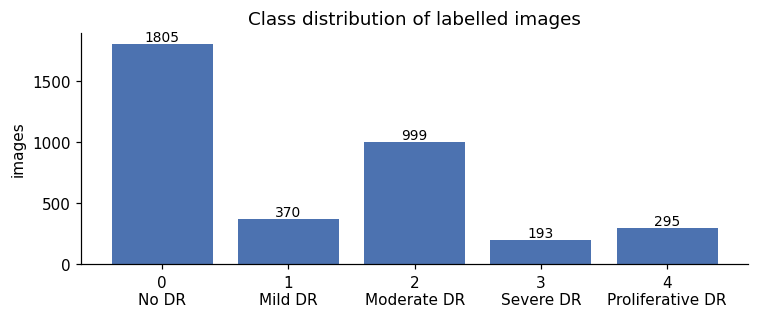

In [13]:
print_tree(dataset_path, max_depth=1)
print()
labels_df, discovery_info = discover_dataset(dataset_path, DATASET_OVERRIDES)

counts = labels_df.label.value_counts().sort_index()
assert set(counts.index) == set(GRADE_NAMES), f'Expected grades 0-4, found {sorted(counts.index)}'
dist = pd.DataFrame({'grade': [GRADE_NAMES[g] for g in counts.index], 'n_images': counts.values,
                     'percent': (100 * counts / counts.sum()).round(2).values}, index=counts.index)
display(dist)
print(f'Imbalance ratio (largest/smallest grade): {counts.max() / counts.min():.1f}')
HAS_PATIENT_IDS = 'patient_id' in labels_df.columns
if not HAS_PATIENT_IDS:
    display(Markdown('> **Limitation:** no patient identifier was found, so images from the same patient '
                     '(e.g. left/right eyes, repeat visits) cannot be kept in one split. Splitting is '
                     'stratified at image level, with exact/near-duplicate clusters kept together.'))
display(Markdown(f"Label semantics: the `{discovery_info.get('label_col', 'folder')}` values are integers 0–4. "
                 'For the APTOS-2019 data these are documented as the ICDR severity scale '
                 '(0 No DR … 4 Proliferative DR). Confirm this against the dataset documentation for any other source.'))

fig, ax = plt.subplots(figsize=(7, 3))
ax.bar([f'{g}\n{GRADE_NAMES[g]}' for g in counts.index], counts.values, color='#4C72B0')
for i, v in enumerate(counts.values):
    ax.text(i, v, str(v), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('images'); ax.set_title('Class distribution of labelled images')
plt.tight_layout(); plt.savefig(FIG_DIR / 'class_distribution.png', bbox_inches='tight'); plt.show()

Loading existing standardised cache from Drive ...
Readable images: 3662 | unreadable (excluded): 0
Fundus crop applied to 3662 images; original sizes ranged 474-4288 px wide.


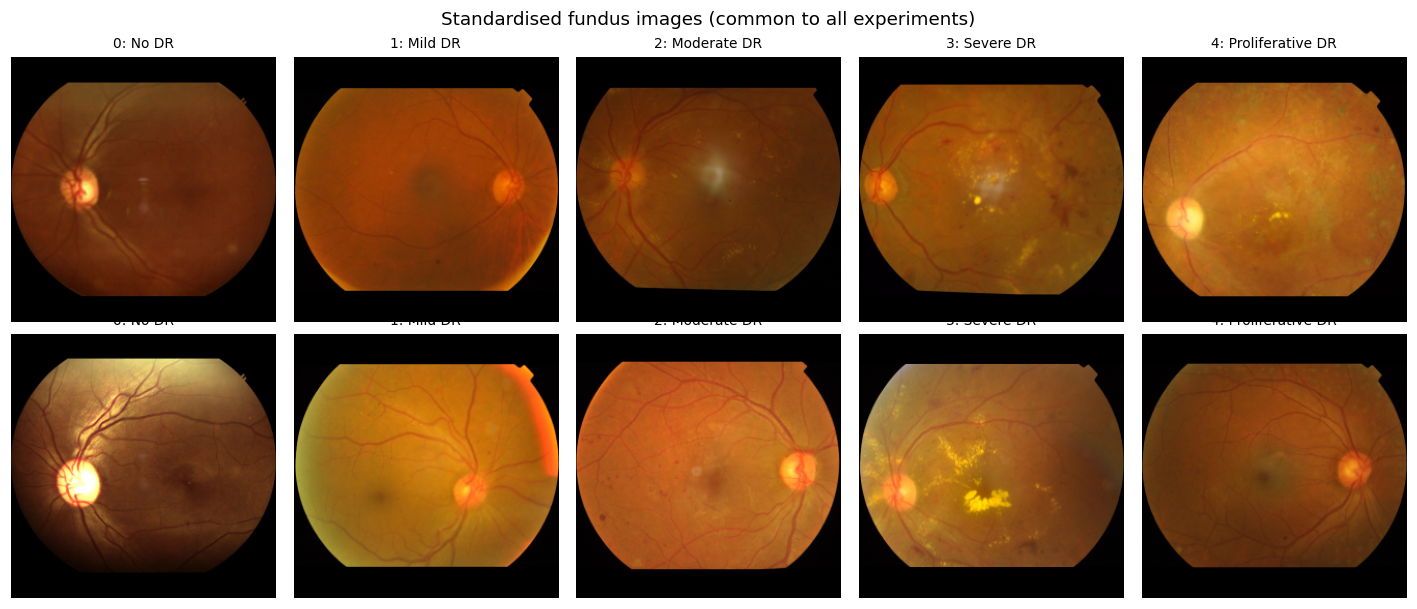

In [14]:
STD_PARAMS = dict(PP.DEFAULT_STANDARDISATION, cache_size=PROTOCOL['cache_size'],
                  crop_threshold=PROTOCOL['crop_threshold'])
S = STD_PARAMS['cache_size']
ids_fingerprint = hashlib.sha256('\n'.join(labels_df.image_id).encode()).hexdigest()[:16]
cache_tag = f'standardised_{S}_{ids_fingerprint}'
drive_npy, drive_idx = SHARED_CACHE / f'{cache_tag}.npy', SHARED_CACHE / f'{cache_tag}_index.csv'
local_npy = LOCAL_CACHE / f'{cache_tag}.npy'

def _process_one(i_path):
    i, path = i_path
    rec = dict(row=i, readable=False, md5=None, phash=None, dhash=None, error=None)
    try:
        b = PP.read_bytes(path)
        rec['md5'] = PP.md5_bytes(b)
        rgb = PP.decode_rgb(b)
        if rgb is None:
            rec['error'] = 'decode failed'
            return rec, None
        std, meta = PP.standardise(rgb, **STD_PARAMS)
        gray = Image.fromarray(cv2.cvtColor(std, cv2.COLOR_RGB2GRAY))
        rec.update(meta, readable=True, phash=str(imagehash.phash(gray)), dhash=str(imagehash.dhash(gray)))
        return rec, std
    except Exception as e:  # noqa: BLE001
        rec['error'] = f'{type(e).__name__}: {e}'
        return rec, None

if drive_npy.exists() and drive_idx.exists():
    print('Loading existing standardised cache from Drive ...')
    if not local_npy.exists():
        shutil.copy(drive_npy, local_npy)
    STD = np.load(local_npy)
    cache_index = pd.read_csv(drive_idx, dtype={'phash': str, 'dhash': str, 'md5': str})
    assert len(cache_index) == len(labels_df) == len(STD) and (cache_index.image_id == labels_df.image_id).all(), \
        'Cache does not match the labelled image list; delete the shared_cache folder to rebuild.'
else:
    print(f'Building standardised cache for {len(labels_df)} images (one-off, shared by all notebooks) ...')
    STD = np.lib.format.open_memmap(local_npy, mode='w+', dtype=np.uint8, shape=(len(labels_df), S, S, 3))
    records, t0 = [], time.time()
    with ThreadPoolExecutor(max_workers=8) as ex:
        for k, (rec, img) in enumerate(ex.map(_process_one, enumerate(labels_df.path))):
            records.append(rec)
            STD[rec['row']] = img if img is not None else 0
            if (k + 1) % 500 == 0:
                print(f'  {k + 1}/{len(labels_df)} images ({time.time() - t0:.0f}s)')
    STD.flush()
    cache_index = pd.DataFrame(records).sort_values('row').reset_index(drop=True)
    cache_index.insert(0, 'image_id', labels_df.image_id.values)
    cache_index['label'] = labels_df.label.values
    shutil.copy(local_npy, drive_npy)
    cache_index.to_csv(drive_idx, index=False)
    STD = np.load(local_npy)
    print(f'Cache built in {time.time() - t0:.0f}s and saved to {SHARED_CACHE}')

unreadable = cache_index[~cache_index.readable]
print(f'Readable images: {cache_index.readable.sum()} | unreadable (excluded): {len(unreadable)}')
if len(unreadable):
    display(unreadable[['image_id', 'error']])
print(f"Fundus crop applied to {cache_index.cropped.fillna(False).astype(bool).sum()} images; "
      f"original sizes ranged {int(cache_index.orig_w.min())}-{int(cache_index.orig_w.max())} px wide.")

fig, axes = plt.subplots(2, 5, figsize=(13, 5.6))
rng_vis = np.random.default_rng(0)
for g in range(5):
    rows = np.where((cache_index.label == g) & cache_index.readable)[0]
    for r in range(2):
        ax = axes[r, g]; ax.axis('off')
        if len(rows) > r:
            ax.imshow(STD[rng_vis.choice(rows)]); ax.set_title(f'{g}: {GRADE_NAMES[g]}', fontsize=9)
plt.suptitle('Standardised fundus images (common to all experiments)'); plt.tight_layout()
plt.savefig(FIG_DIR / 'standardised_examples.png', bbox_inches='tight'); plt.show()

Hash candidates: 16638 | confirmed by vessel-pattern NCC >= 0.9: 148
NCC of candidate pairs (quantiles 0/25/50/75/100%): [-0.239, 0.007, 0.073, 0.147, 1.0]
Exact-duplicate files (beyond first copy): 128
Duplicate pairs linked (exact + confirmed near): 276 | images in duplicate clusters: 270 | largest cluster: 4
Conflicting-grade duplicate clusters: 37 (79 images excluded)
Images retained for the study: 3486 of 3662 labelled; excluded: 176


,excluded images
category,
redundant duplicate (same grade),97
duplicate with conflicting grades,79


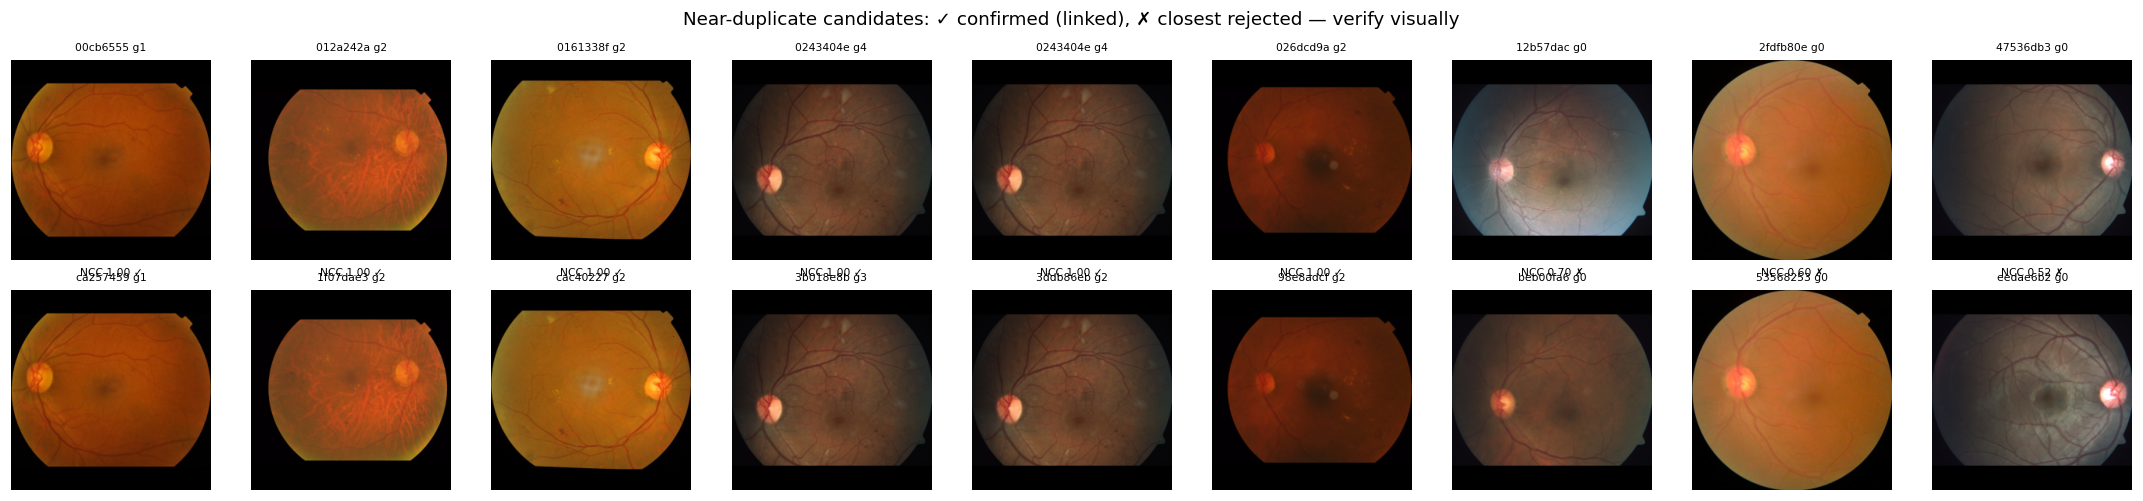

In [15]:
readable = cache_index[cache_index.readable].copy()

def hex_to_uint64(hs):
    return np.array([int(h, 16) for h in hs], dtype=np.uint64)

def popcount64(x):
    if hasattr(np, 'bitwise_count'):
        return np.bitwise_count(x)
    return np.unpackbits(x.view(np.uint8).reshape(*x.shape, 8), axis=-1).sum(-1)

ph, dh = hex_to_uint64(readable.phash), hex_to_uint64(readable.dhash)
T_HAM = PROTOCOL['near_duplicate_hamming']
T_NCC = PROTOCOL['near_duplicate_ncc']
candidates = []
for i0 in range(0, len(ph), 512):
    dp = popcount64(ph[i0:i0 + 512, None] ^ ph[None, :])
    dd = popcount64(dh[i0:i0 + 512, None] ^ dh[None, :])
    ii, jj = np.where((dp <= T_HAM) & (dd <= T_HAM))
    keep = (ii + i0) < jj
    candidates += [(int(a + i0), int(b), int(dp[a, b]), int(dd[a, b])) for a, b in zip(ii[keep], jj[keep])]
_sig_cache = {}
def sig(pos):
    if pos not in _sig_cache:
        _sig_cache[pos] = PP.detail_signature(STD[int(readable.iloc[pos].row)])
    return _sig_cache[pos]
cand_df = pd.DataFrame(candidates, columns=['a', 'b', 'phash_d', 'dhash_d'])
cand_df['ncc'] = [float(sig(a) @ sig(b)) for a, b in zip(cand_df.a, cand_df.b)] if len(cand_df) else []
confirmed = cand_df[cand_df.ncc >= T_NCC]
pairs = [tuple(r) for r in confirmed[['a', 'b', 'phash_d', 'dhash_d']].astype(int).itertuples(index=False)]
print(f'Hash candidates: {len(cand_df)} | confirmed by vessel-pattern NCC >= {T_NCC}: {len(confirmed)}')
if len(cand_df):
    print('NCC of candidate pairs (quantiles 0/25/50/75/100%):', np.round(np.quantile(cand_df.ncc, [0, .25, .5, .75, 1]), 3).tolist())
md5_groups = readable.groupby('md5').indices
for idxs in md5_groups.values():
    idxs = list(idxs)
    pairs += [(idxs[0], j, -1, -1) for j in idxs[1:]]

parent = list(range(len(readable)))
def find(a):
    while parent[a] != a:
        parent[a] = parent[parent[a]]; a = parent[a]
    return a
for a, b, *_ in pairs:
    ra, rb = find(a), find(b)
    if ra != rb: parent[max(ra, rb)] = min(ra, rb)
readable['dup_cluster'] = [find(i) for i in range(len(readable))]

if HAS_PATIENT_IDS:   # images of one patient must also share a split
    pmap = labels_df.set_index('image_id').patient_id
    readable['patient_id'] = readable.image_id.map(pmap)
    for _, idx in readable.groupby('patient_id').indices.items():
        for j in idx[1:]:
            ra, rb = find(idx[0]), find(j)
            if ra != rb: parent[max(ra, rb)] = min(ra, rb)
    readable['group_cluster'] = [find(i) for i in range(len(readable))]
else:
    readable['group_cluster'] = readable.dup_cluster

csize = readable.dup_cluster.map(readable.dup_cluster.value_counts())
n_exact = sum(len(v) - 1 for v in md5_groups.values() if len(v) > 1)
print(f'Exact-duplicate files (beyond first copy): {n_exact}')
print(f'Duplicate pairs linked (exact + confirmed near): {len(pairs)} | images in duplicate clusters: {(csize > 1).sum()} '
      f'| largest cluster: {csize.max()}')
if csize.max() > 20:
    print('WARNING: a very large duplicate cluster suggests hash collisions; inspect the pairs below '
          'and consider lowering near_duplicate_hamming (this changes the protocol for ALL notebooks).')

labels_per_cluster = readable.groupby('dup_cluster').label.nunique()
conflict_clusters = set(labels_per_cluster[labels_per_cluster > 1].index)
excluded = [dict(image_id=r.image_id, label=r.label, category='unreadable file', reason=str(r.error))
            for r in unreadable.itertuples()]
kept_rows = []
for cl, grp in readable.groupby('dup_cluster'):
    if cl in conflict_clusters:
        excluded += [dict(image_id=r.image_id, label=r.label, category='duplicate with conflicting grades',
                          reason=f'cluster grades {sorted(int(v) for v in grp.label.unique())}') for r in grp.itertuples()]
    elif len(grp) > 1:
        rep = grp.assign(area=grp.orig_h * grp.orig_w).sort_values(['area', 'image_id'], ascending=[False, True]).iloc[0]
        kept_rows.append(rep.name)
        excluded += [dict(image_id=r.image_id, label=r.label, category='redundant duplicate (same grade)',
                          reason=f'duplicate of {rep.image_id}') for r in grp.itertuples() if r.Index != rep.name]
    else:
        kept_rows.append(grp.index[0])
clean = readable.loc[sorted(kept_rows)].copy()
excluded_df = pd.DataFrame(excluded, columns=['image_id', 'label', 'category', 'reason'])
print(f'Conflicting-grade duplicate clusters: {len(conflict_clusters)} '
      f'({readable.dup_cluster.isin(conflict_clusters).sum()} images excluded)')
print(f'Images retained for the study: {len(clean)} of {len(labels_df)} labelled; excluded: {len(excluded_df)}')
display(excluded_df.category.value_counts().rename('excluded images').to_frame())

show = [(int(r.a), int(r.b), f'NCC {r.ncc:.2f} ✓') for r in confirmed.head(6).itertuples()]
show += [(int(r.a), int(r.b), f'NCC {r.ncc:.2f} ✗') for r in cand_df[cand_df.ncc < T_NCC].sort_values('ncc', ascending=False).head(3).itertuples()]
if show:
    fig, axes = plt.subplots(2, len(show), figsize=(2.2 * len(show), 4.6))
    axes = np.array(axes).reshape(2, -1)
    for k, (a, b, lab) in enumerate(show):
        for r, idx in enumerate((a, b)):
            row = readable.iloc[idx]
            axes[r, k].imshow(STD[int(row.row)]); axes[r, k].axis('off')
            axes[r, k].set_title(f'{row.image_id[:8]} g{row.label}', fontsize=7)
        axes[0, k].text(0.5, -0.08, lab, transform=axes[0, k].transAxes, ha='center', fontsize=7)
    plt.suptitle('Near-duplicate candidates: ✓ confirmed (linked), ✗ closest rejected — verify visually'); plt.tight_layout()
    plt.savefig(FIG_DIR / 'near_duplicate_pairs.png', bbox_inches='tight'); plt.show()

In [16]:
from sklearn.model_selection import StratifiedGroupKFold, train_test_split

dataset_fingerprint = hashlib.sha256('\n'.join(f'{r.image_id}:{r.md5}:{r.label}' for r in clean.itertuples()).encode()).hexdigest()[:16]
split_settings = dict(fractions=PROTOCOL['split_fractions'], seed=PROTOCOL['split_seed'],
                      near_duplicate_hamming=T_HAM, near_duplicate_ncc=T_NCC, duplicate_policy=PROTOCOL['duplicate_policy'],
                      conflicting_duplicate_policy=PROTOCOL['conflicting_duplicate_policy'])
manifest_path, split_meta_path = SPLIT_DIR / 'split_manifest.csv', SPLIT_DIR / 'split_meta.json'

def make_split(df, fr, seed):
    y, groups = df.label.values, df.group_cluster.values
    if len(np.unique(groups)) == len(groups):
        idx = np.arange(len(df))
        tv, te = train_test_split(idx, test_size=fr['test'], stratify=y, random_state=seed)
        tr, va = train_test_split(tv, test_size=fr['val'] / (1 - fr['test']), stratify=y[tv], random_state=seed)
        method = 'stratified image-level (train_test_split); duplicate clusters already collapsed'
    else:
        sg = StratifiedGroupKFold(n_splits=max(2, round(1 / fr['test'])), shuffle=True, random_state=seed)
        tv, te = next(sg.split(np.zeros(len(y)), y, groups))
        sg2 = StratifiedGroupKFold(n_splits=max(2, round((1 - fr['test']) / fr['val'])), shuffle=True, random_state=seed)
        a, b = next(sg2.split(np.zeros(len(tv)), y[tv], groups[tv]))
        tr, va = tv[a], tv[b]
        method = 'StratifiedGroupKFold (groups = patient / duplicate clusters)'
    split = np.empty(len(df), dtype=object)
    split[tr], split[va], split[te] = 'train', 'val', 'test'
    return split, method

if manifest_path.exists():
    manifest = pd.read_csv(manifest_path)
    meta = json.loads(split_meta_path.read_text())
    problems = []
    if meta['dataset_fingerprint'] != dataset_fingerprint: problems.append('dataset fingerprint differs')
    if meta['settings'] != to_jsonable(split_settings): problems.append('split settings differ')
    if set(manifest.image_id) != set(clean.image_id): problems.append('image set differs')
    if problems:
        raise RuntimeError('Saved split is inconsistent with this run: ' + '; '.join(problems) +
                           f'. If the dataset/protocol was changed intentionally, delete {SPLIT_DIR} and rerun ALL notebooks.')
    print(f"Loaded shared split created by {meta['created_by']} on {meta['created_at']} (manifest sha {meta['manifest_sha256'][:12]})")
else:
    split, split_method = make_split(clean.reset_index(drop=True), PROTOCOL['split_fractions'], PROTOCOL['split_seed'])
    manifest = clean.reset_index(drop=True)[['image_id', 'label', 'md5', 'dup_cluster', 'group_cluster']].copy()
    manifest['split'] = split
    manifest.to_csv(manifest_path, index=False)
    excluded_df.to_csv(SPLIT_DIR / 'excluded_images.csv', index=False)
    meta = dict(created_by=EXPERIMENT_ID, created_at=time.strftime('%Y-%m-%d %H:%M:%S'), method=split_method,
                settings=split_settings, dataset_fingerprint=dataset_fingerprint,
                manifest_sha256=hashlib.sha256(manifest_path.read_bytes()).hexdigest(),
                patient_ids_available=HAS_PATIENT_IDS,
                discovery={k: (v[:100] if isinstance(v, list) else v) for k, v in discovery_info.items()},
                n_retained=len(manifest), n_excluded=len(excluded_df))
    save_json(meta, split_meta_path)
    print(f'Created and saved new shared split: {split_method}')

SPLIT_SHA = hashlib.sha256(manifest_path.read_bytes()).hexdigest()[:12]
manifest = manifest.merge(readable[['image_id', 'row']], on='image_id', how='left')
assert manifest.row.notna().all()
# --- leakage checks ---
for col in ('group_cluster', 'md5', 'dup_cluster'):
    n_split = manifest.groupby(col).split.nunique()
    assert (n_split == 1).all(), f'LEAKAGE: {col} spans several splits'
assert manifest.image_id.is_unique
print('Leakage checks passed: no image, file hash, duplicate cluster or patient group spans two splits.')

tab = pd.crosstab(manifest.label.map(lambda g: f'{g} {GRADE_NAMES[g]}'), manifest.split)[['train', 'val', 'test']]
tab.loc['total'] = tab.sum()
display(tab)
min_eval = tab.drop('total')[['val', 'test']].values.min()
if min_eval < 10:
    raise RuntimeError(f'A grade has only {min_eval} images in val/test: estimates would be unreliable. '
                       'Use a larger dataset or switch to stratified k-fold cross-validation.')
print(f'Split hash: {SPLIT_SHA}')

Loaded shared split created by 03_Green_Channel on 2026-10-19 18:31:51 (manifest sha fb73b8c60281)
Leakage checks passed: no image, file hash, duplicate cluster or patient group spans two splits.


split,train,val,test
label,,,
0 No DR,1258,269,269
1 Mild DR,236,51,51
2 Moderate DR,645,138,138
3 Severe DR,117,25,25
4 Proliferative DR,184,40,40
total,2440,523,523


Split hash: fb73b8c60281


Preprocessing method: green_channel
Parameters: {
  "source_channel": "G (RGB index 1)",
  "replicate_to": 3
}
Preprocessed 3486 images in 0.9s (0.27 ms/image at 256x256)


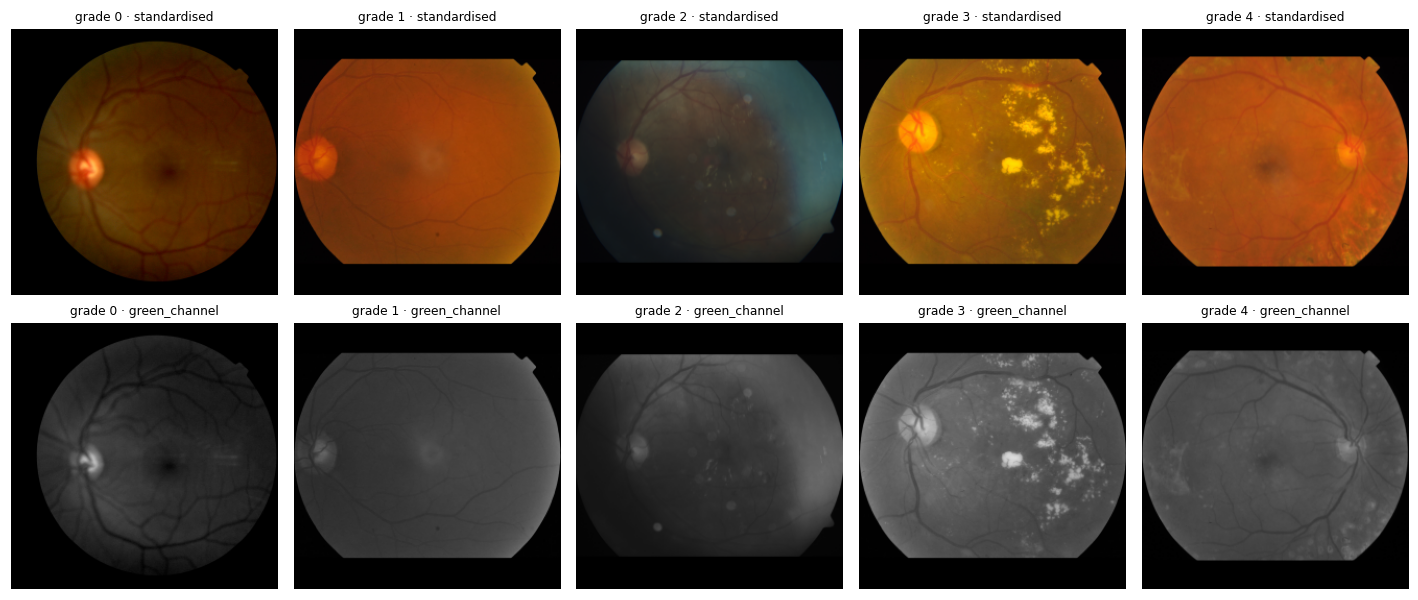

Fine-detail retention (green channel, inside fundus mask; 1.0 = unchanged):
{
  "laplacian_var_ratio_green_mean": 1.0,
  "laplacian_var_ratio_green_sd": 0.0,
  "psnr_green_median": Infinity,
  "n_images": 200
}


In [17]:
METHOD_PARAMS = PP.DEFAULT_PARAMS[PREPROCESSING_METHOD]
print(f'Preprocessing method: {PREPROCESSING_METHOD}\nParameters: {json.dumps(METHOD_PARAMS, indent=2)}')

order = {'train': 0, 'val': 1, 'test': 2}
manifest = manifest.sort_values(['split', 'image_id'], key=lambda s: s.map(order) if s.name == 'split' else s).reset_index(drop=True)
t0 = time.time()
X = np.empty((len(manifest), S, S, 3), dtype=np.uint8)
for i, r in enumerate(manifest.row.astype(int).values):
    X[i] = PP.apply_preprocessing(STD[r], PREPROCESSING_METHOD, METHOD_PARAMS)
PREPROC_SECONDS = time.time() - t0
print(f'Preprocessed {len(X)} images in {PREPROC_SECONDS:.1f}s ({1000 * PREPROC_SECONDS / len(X):.2f} ms/image at {S}x{S})')
Y = manifest.label.values.astype(int)
IDX = {s: np.where(manifest.split.values == s)[0] for s in ('train', 'val', 'test')}
GROUPS_TEST = manifest.group_cluster.values[IDX['test']]

# visual comparison: one training image per grade, standardised vs preprocessed
fig, axes = plt.subplots(2, 5, figsize=(13, 5.6))
for g in range(5):
    i = IDX['train'][Y[IDX['train']] == g][0]
    axes[0, g].imshow(STD[int(manifest.row[i])]); axes[0, g].set_title(f'grade {g} · standardised', fontsize=8)
    axes[1, g].imshow(X[i]); axes[1, g].set_title(f'grade {g} · {PREPROCESSING_METHOD}', fontsize=8)
    for a in axes[:, g]: a.axis('off')
plt.tight_layout(); plt.savefig(FIG_DIR / 'preprocessing_examples.png', bbox_inches='tight'); plt.show()

# information-retention diagnostics on a fixed sample of TRAINING images only
sample = np.random.default_rng(0).choice(IDX['train'], size=min(200, len(IDX['train'])), replace=False)
ret = np.array([PP.detail_retention(STD[int(manifest.row[i])], X[i]) for i in sample])
DETAIL_RETENTION = dict(laplacian_var_ratio_green_mean=float(np.nanmean(ret[:, 0])),
                        laplacian_var_ratio_green_sd=float(np.nanstd(ret[:, 0])),
                        psnr_green_median=float(np.median(ret[:, 1])) if np.isfinite(ret[:, 1]).any() else float('inf'),
                        n_images=len(sample))
print('Fine-detail retention (green channel, inside fundus mask; 1.0 = unchanged):')
print(json.dumps(DETAIL_RETENTION, indent=2))
save_json(dict(method=PREPROCESSING_METHOD, params=METHOD_PARAMS, standardisation=STD_PARAMS,
               seconds_total=PREPROC_SECONDS, n_images=len(X), detail_retention=DETAIL_RETENTION), EXP_DIR / 'preprocessing_record.json')

,grade,train_count,loss_weight
0,No DR,1258,0.388
1,Mild DR,236,2.068
2,Moderate DR,645,0.757
3,Severe DR,117,4.171
4,Proliferative DR,184,2.652


Batch tensor shape: (32, 3, 224, 224) | dtype torch.float32


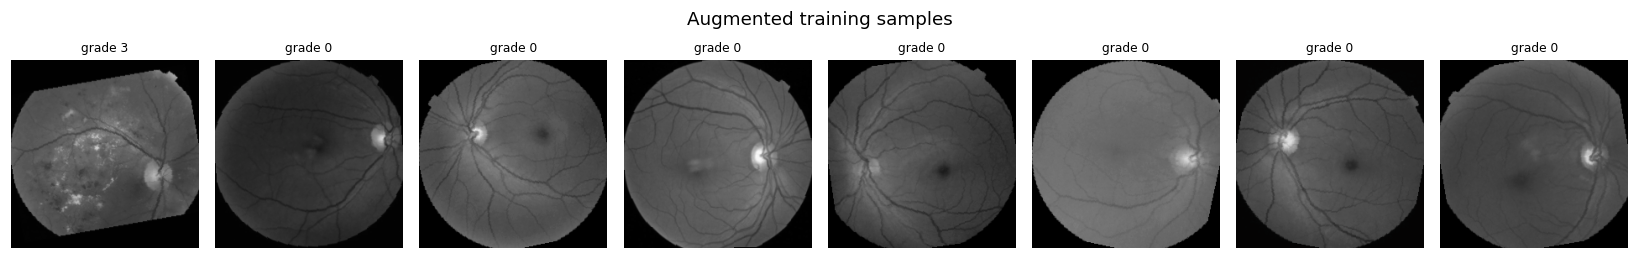

In [18]:
AUG = PROTOCOL['augmentation']
IMG = PROTOCOL['image_size']
train_tf = PP.build_train_transform(IMG, AUG)
eval_tf = PP.build_eval_transform(IMG)

class ArrayDataset(Dataset):
    def __init__(self, images, labels, transform):
        self.images, self.labels, self.transform = images, labels, transform
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        return self.transform(self.images[i]), int(self.labels[i])

def seed_worker(worker_id):
    s = torch.initial_seed() % 2 ** 32
    np.random.seed(s); random.seed(s)

def make_loader(split, train, seed):
    ds = ArrayDataset(X[IDX[split]], Y[IDX[split]], train_tf if train else eval_tf)
    g = torch.Generator(); g.manual_seed(seed)
    return DataLoader(ds, batch_size=PROTOCOL['batch_size'], shuffle=train, drop_last=train,
                      num_workers=RUN_OPTIONS['num_workers'], pin_memory=DEVICE.type == 'cuda',
                      worker_init_fn=seed_worker, generator=g, persistent_workers=False)

n_k = np.bincount(Y[IDX['train']], minlength=5)
CLASS_WEIGHTS = len(IDX['train']) / (5 * n_k)
display(pd.DataFrame({'grade': [GRADE_NAMES[k] for k in range(5)], 'train_count': n_k,
                      'loss_weight': CLASS_WEIGHTS.round(3)}))

xb, yb = next(iter(make_loader('train', True, 0)))
assert xb.shape[1:] == (3, IMG, IMG), xb.shape
print('Batch tensor shape:', tuple(xb.shape), '| dtype', xb.dtype)
mean, std = torch.tensor(PP.IMAGENET_MEAN).view(3, 1, 1), torch.tensor(PP.IMAGENET_STD).view(3, 1, 1)
fig, axes = plt.subplots(1, 8, figsize=(15, 2.4))
for k in range(8):
    axes[k].imshow((xb[k] * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()); axes[k].axis('off')
    axes[k].set_title(f'grade {int(yb[k])}', fontsize=8)
plt.suptitle('Augmented training samples'); plt.tight_layout()
plt.savefig(FIG_DIR / 'augmented_samples.png', bbox_inches='tight'); plt.show()

In [19]:
ALLOW_RANDOM_INIT = SMOKE_TEST   # never True in a real run
arch_rows = []
for arch in PROTOCOL['architectures']:
    for att in ('cbam', 'none'):
        m, prov = MD.build_model(arch, attention=att, reduction=PROTOCOL['cbam_reduction'],
                                 spatial_kernel=PROTOCOL['cbam_spatial_kernel'], dropout=PROTOCOL['head_dropout'],
                                 pretrained=True, allow_random_init=ALLOW_RANDOM_INIT)
        with torch.no_grad():
            out = m.eval()(torch.zeros(1, 3, IMG, IMG))
        assert out.shape == (1, 5)
        arch_rows.append(dict(architecture=arch, attention=att, weights=prov['weights'],
                              pretrained_loaded=prov['pretrained_loaded'], feature_channels=prov['feature_channels'],
                              params_total_M=prov['params_total'] / 1e6, params_backbone_M=prov['params_backbone'] / 1e6,
                              params_new=prov['params_new']))
        del m
arch_table = pd.DataFrame(arch_rows)
display(arch_table.round(3))
if not ALLOW_RANDOM_INIT and not arch_table.pretrained_loaded.all():
    raise RuntimeError('Some pretrained weights failed to load; the protocol requires ImageNet initialisation.')
arch_table.to_csv(EXP_DIR / 'architectures.csv', index=False)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 191MB/s]


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 183MB/s]


Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 164MB/s]


Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 154MB/s]


,architecture,attention,weights,pretrained_loaded,feature_channels,params_total_M,params_backbone_M,params_new
0,EfficientNetB0,cbam,EfficientNet_B0_Weights.IMAGENET1K_V1,True,1280,4.219,4.008,211303
1,EfficientNetB0,none,EfficientNet_B0_Weights.IMAGENET1K_V1,True,1280,4.014,4.008,6405
2,ResNet50,cbam,ResNet50_Weights.IMAGENET1K_V1,True,2048,24.043,23.508,534631
3,ResNet50,none,ResNet50_Weights.IMAGENET1K_V1,True,2048,23.518,23.508,10245
4,DenseNet121,cbam,DenseNet121_Weights.IMAGENET1K_V1,True,1024,7.090,6.954,136295
5,DenseNet121,none,DenseNet121_Weights.IMAGENET1K_V1,True,1024,6.959,6.954,5125
6,ConvNeXtTiny,cbam,ConvNeXt_Tiny_Weights.IMAGENET1K_V1,True,768,27.898,27.819,79207
7,ConvNeXtTiny,none,ConvNeXt_Tiny_Weights.IMAGENET1K_V1,True,768,27.824,27.819,5381


In [20]:
cb = MD.CBAM(64, reduction=PROTOCOL['cbam_reduction'], spatial_kernel=PROTOCOL['cbam_spatial_kernel'])
f = torch.randn(2, 64, 7, 7)
o = cb(f)
print('CBAM check: in', tuple(f.shape), '-> out', tuple(o.shape), '| spatial map', tuple(cb.last_spatial_map.shape),
      '| params', sum(p.numel() for p in cb.parameters()))
m_tmp, _ = MD.build_model('ResNet50', attention='cbam', pretrained=False)
assert any(isinstance(mod, MD.CBAM) for mod in m_tmp.modules()), 'CBAM not present in the forward graph'
m_tmp2, _ = MD.build_model('ResNet50', attention='none', pretrained=False)
assert not any(isinstance(mod, MD.CBAM) for mod in m_tmp2.modules())
del m_tmp, m_tmp2
print('Verified: cbam variants contain CBAM modules, noattn variants do not.')

CBAM check: in (2, 64, 7, 7) -> out (2, 64, 7, 7) | spatial map (2, 1, 7, 7) | params 1122
Verified: cbam variants contain CBAM modules, noattn variants do not.


In [21]:
PRIMARY = PROTOCOL['primary_metric']

@torch.no_grad()
def predict(model, loader, criterion=None):
    model.eval()
    probs, labels, loss_sum, n = [], [], 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(xb)
        logits = logits.float()
        if criterion is not None:
            loss_sum += criterion(logits, yb).item() * len(yb); n += len(yb)
        probs.append(torch.softmax(logits, 1).cpu().numpy()); labels.append(yb.cpu().numpy())
    return np.concatenate(probs), np.concatenate(labels), (loss_sum / n if n else float('nan'))

def quick_scores(y, prob):
    cm = MT.cm_fast(y, prob.argmax(1))
    return dict(acc=MT.accuracy_from_cm(cm), macro_f1=MT.macro_f1_from_cm(cm), qwk=MT.qwk_from_cm(cm))

def run_name(arch, attention, seed):
    return EXP_DIR / arch / f"{'cbam' if attention == 'cbam' else 'noattn'}_seed{seed}"

def train_run(arch, attention='cbam', seed=42):
    rdir = run_name(arch, attention, seed); rdir.mkdir(parents=True, exist_ok=True)
    done_file, last_ckpt, best_file = rdir / 'run_complete.json', rdir / 'last_checkpoint.pt', rdir / 'best_model.pt'
    if done_file.exists() and not RUN_OPTIONS['force_retrain']:
        print(f'[skip] {rdir.relative_to(OUTPUT_ROOT)} already complete')
        return json.loads(done_file.read_text())
    set_seed(seed)
    model, prov = MD.build_model(arch, attention=attention, reduction=PROTOCOL['cbam_reduction'],
                                 spatial_kernel=PROTOCOL['cbam_spatial_kernel'], dropout=PROTOCOL['head_dropout'],
                                 pretrained=True, allow_random_init=ALLOW_RANDOM_INIT)
    model = model.to(DEVICE).to(memory_format=torch.channels_last)
    criterion = nn.CrossEntropyLoss(weight=torch.tensor(CLASS_WEIGHTS, dtype=torch.float32, device=DEVICE))
    opt = torch.optim.AdamW([{'params': model.backbone.parameters(), 'lr': PROTOCOL['lr_backbone']},
                             {'params': model.head_parameters(), 'lr': PROTOCOL['lr_head']}],
                            weight_decay=PROTOCOL['weight_decay'])
    E = PROTOCOL['max_epochs']
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda e: 0.5 * (1 + math.cos(math.pi * e / E)))
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    train_loader, val_loader = make_loader('train', True, seed), make_loader('val', False, seed)
    hist, start, best, best_epoch, bad = [], 0, -float('inf'), -1, 0
    if last_ckpt.exists() and not RUN_OPTIONS['force_retrain']:
        ck = torch.load(last_ckpt, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ck['model']); opt.load_state_dict(ck['optimizer'])
        sched.load_state_dict(ck['scheduler']); scaler.load_state_dict(ck['scaler'])
        hist, start, best, best_epoch, bad = ck['history'], ck['epoch'] + 1, ck['best'], ck['best_epoch'], ck['bad']
        torch.set_rng_state(ck['rng_torch']); np.random.set_state(ck['rng_numpy']); random.setstate(ck['rng_python'])
        if DEVICE.type == 'cuda' and ck.get('rng_cuda') is not None: torch.cuda.set_rng_state_all(ck['rng_cuda'])
        train_loader.generator.set_state(ck['rng_loader'])
        print(f'[resume] {rdir.name} from epoch {start}')
    t_start = time.time() - (hist[-1]['elapsed_s'] if hist else 0.0)
    for epoch in range(start, E):
        frozen = epoch < PROTOCOL['warmup_frozen_epochs']
        MD.set_backbone_trainable(model, not frozen)
        model.train()
        if frozen: model.backbone.eval()
        tl, tc, tn = 0.0, 0, 0
        for xb, yb in train_loader:
            xb = xb.to(DEVICE, non_blocking=True).to(memory_format=torch.channels_last); yb = yb.to(DEVICE)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(xb); loss = criterion(logits.float(), yb)
            if not torch.isfinite(loss):
                raise FloatingPointError(f'Non-finite loss at epoch {epoch} in {rdir}')
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], PROTOCOL['grad_clip_norm'])
            scaler.step(opt); scaler.update()
            tl += loss.item() * len(yb); tc += (logits.argmax(1) == yb).sum().item(); tn += len(yb)
        sched.step()
        vp, vy, vloss = predict(model, val_loader, criterion)
        vs = quick_scores(vy, vp)
        rec = dict(epoch=epoch, frozen_backbone=frozen, train_loss=tl / tn, train_acc=tc / tn, val_loss=vloss,
                   val_acc=vs['acc'], val_macro_f1=vs['macro_f1'], val_qwk=vs['qwk'],
                   lr_backbone=opt.param_groups[0]['lr'], lr_head=opt.param_groups[1]['lr'],
                   elapsed_s=time.time() - t_start)
        hist.append(rec)
        score = vs[PRIMARY]
        improved = score > best + PROTOCOL['min_delta']
        if improved:
            best, best_epoch, bad = score, epoch, 0
            torch.save(model.state_dict(), best_file)
        elif not frozen:
            bad += 1
        print(f"  ep{epoch:02d} {'F' if frozen else ' '} loss {rec['train_loss']:.3f}/{vloss:.3f} "
              f"acc {rec['train_acc']:.3f}/{vs['acc']:.3f} vF1 {vs['macro_f1']:.3f} vQWK {vs['qwk']:.3f}"
              f"{'  *best' if improved else ''}  [{rec['elapsed_s'] / 60:.1f} min]")
        torch.save(dict(model=model.state_dict(), optimizer=opt.state_dict(), scheduler=sched.state_dict(),
                        scaler=scaler.state_dict(), epoch=epoch, history=hist, best=best, best_epoch=best_epoch, bad=bad,
                        rng_torch=torch.get_rng_state(), rng_numpy=np.random.get_state(), rng_python=random.getstate(),
                        rng_cuda=torch.cuda.get_rng_state_all() if DEVICE.type == 'cuda' else None,
                        rng_loader=train_loader.generator.get_state()), last_ckpt)
        if bad >= PROTOCOL['early_stopping_patience']:
            print(f'  early stopping at epoch {epoch} (best epoch {best_epoch})'); break
    pd.DataFrame(hist).to_csv(rdir / 'history.csv', index=False)
    # final validation metrics of the selected (best) checkpoint
    model.load_state_dict(torch.load(best_file, map_location=DEVICE, weights_only=True))
    vp, vy, vloss = predict(model, val_loader, criterion)
    val_metrics = MT.compute_metrics(vy, vp, GRADE_NAMES); val_metrics['loss'] = vloss
    save_json(val_metrics, rdir / 'val_metrics.json')
    model_cfg = dict(prov, weights_file='best_model.pt', num_classes=5, grade_names=GRADE_NAMES,
                     class_to_index={GRADE_NAMES[k]: k for k in range(5)},
                     preprocessing_method=PREPROCESSING_METHOD, preprocessing_params=METHOD_PARAMS,
                     standardisation=STD_PARAMS, image_size=IMG, color_channels=(
                         'G replicated to 3 channels' if PREPROCESSING_METHOD == 'green_channel' else 'RGB'),
                     normalisation_mean=list(PP.IMAGENET_MEAN), normalisation_std=list(PP.IMAGENET_STD),
                     input_format='file path / bytes / RGB uint8 array of the ORIGINAL fundus photo',
                     experiment_id=EXPERIMENT_ID, seed=seed, best_epoch=best_epoch, protocol=PROTOCOL,
                     protocol_hash=PROTOCOL_HASH, split_sha=SPLIT_SHA, dr_lib_hash=LIB_HASH, environment=ENV)
    save_json(model_cfg, rdir / 'model_config.json')
    summary = dict(run_dir=str(rdir), architecture=arch, attention=attention, seed=seed, best_epoch=best_epoch,
                   epochs_run=len(hist), train_seconds=hist[-1]['elapsed_s'], best_val=val_metrics[PRIMARY],
                   val_qwk=val_metrics['qwk'], val_macro_f1=val_metrics['macro_f1'], val_accuracy=val_metrics['accuracy'],
                   pretrained_loaded=prov['pretrained_loaded'])
    save_json(summary, done_file)
    if not RUN_OPTIONS['keep_last_checkpoint'] and last_ckpt.exists():
        last_ckpt.unlink()
    del model, opt; torch.cuda.empty_cache() if DEVICE.type == 'cuda' else None
    return summary

In [22]:
MAIN_RUNS = {}
for arch in PROTOCOL['architectures']:
    print(f'\n=== {EXPERIMENT_ID} | {arch} | CBAM | seed {PROTOCOL["seed_main"]} ===')
    try:
        MAIN_RUNS[arch] = train_run(arch, 'cbam', PROTOCOL['seed_main'])
    except torch.cuda.OutOfMemoryError as e:
        raise RuntimeError(f'GPU out of memory for {arch}. Reduce PROTOCOL batch_size in ALL notebooks '
                           '(a protocol change) or use a larger GPU.') from e
display(pd.DataFrame(MAIN_RUNS.values())[['architecture', 'best_epoch', 'epochs_run', 'train_seconds',
                                           'val_qwk', 'val_macro_f1', 'val_accuracy']].round(4))


=== 03_Green_Channel | EfficientNetB0 | CBAM | seed 42 ===
[skip] 03_Green_Channel/EfficientNetB0/cbam_seed42 already complete

=== 03_Green_Channel | ResNet50 | CBAM | seed 42 ===
[skip] 03_Green_Channel/ResNet50/cbam_seed42 already complete

=== 03_Green_Channel | DenseNet121 | CBAM | seed 42 ===
[skip] 03_Green_Channel/DenseNet121/cbam_seed42 already complete

=== 03_Green_Channel | ConvNeXtTiny | CBAM | seed 42 ===
[skip] 03_Green_Channel/ConvNeXtTiny/cbam_seed42 already complete


,architecture,best_epoch,epochs_run,train_seconds,val_qwk,val_macro_f1,val_accuracy
0,EfficientNetB0,4,11,197.8838,0.8948,0.6702,0.8126
1,ResNet50,4,11,226.3323,0.9038,0.6324,0.8088
2,DenseNet121,4,11,227.5709,0.8980,0.5866,0.7648
3,ConvNeXtTiny,6,13,284.9545,0.9189,0.6956,0.8394


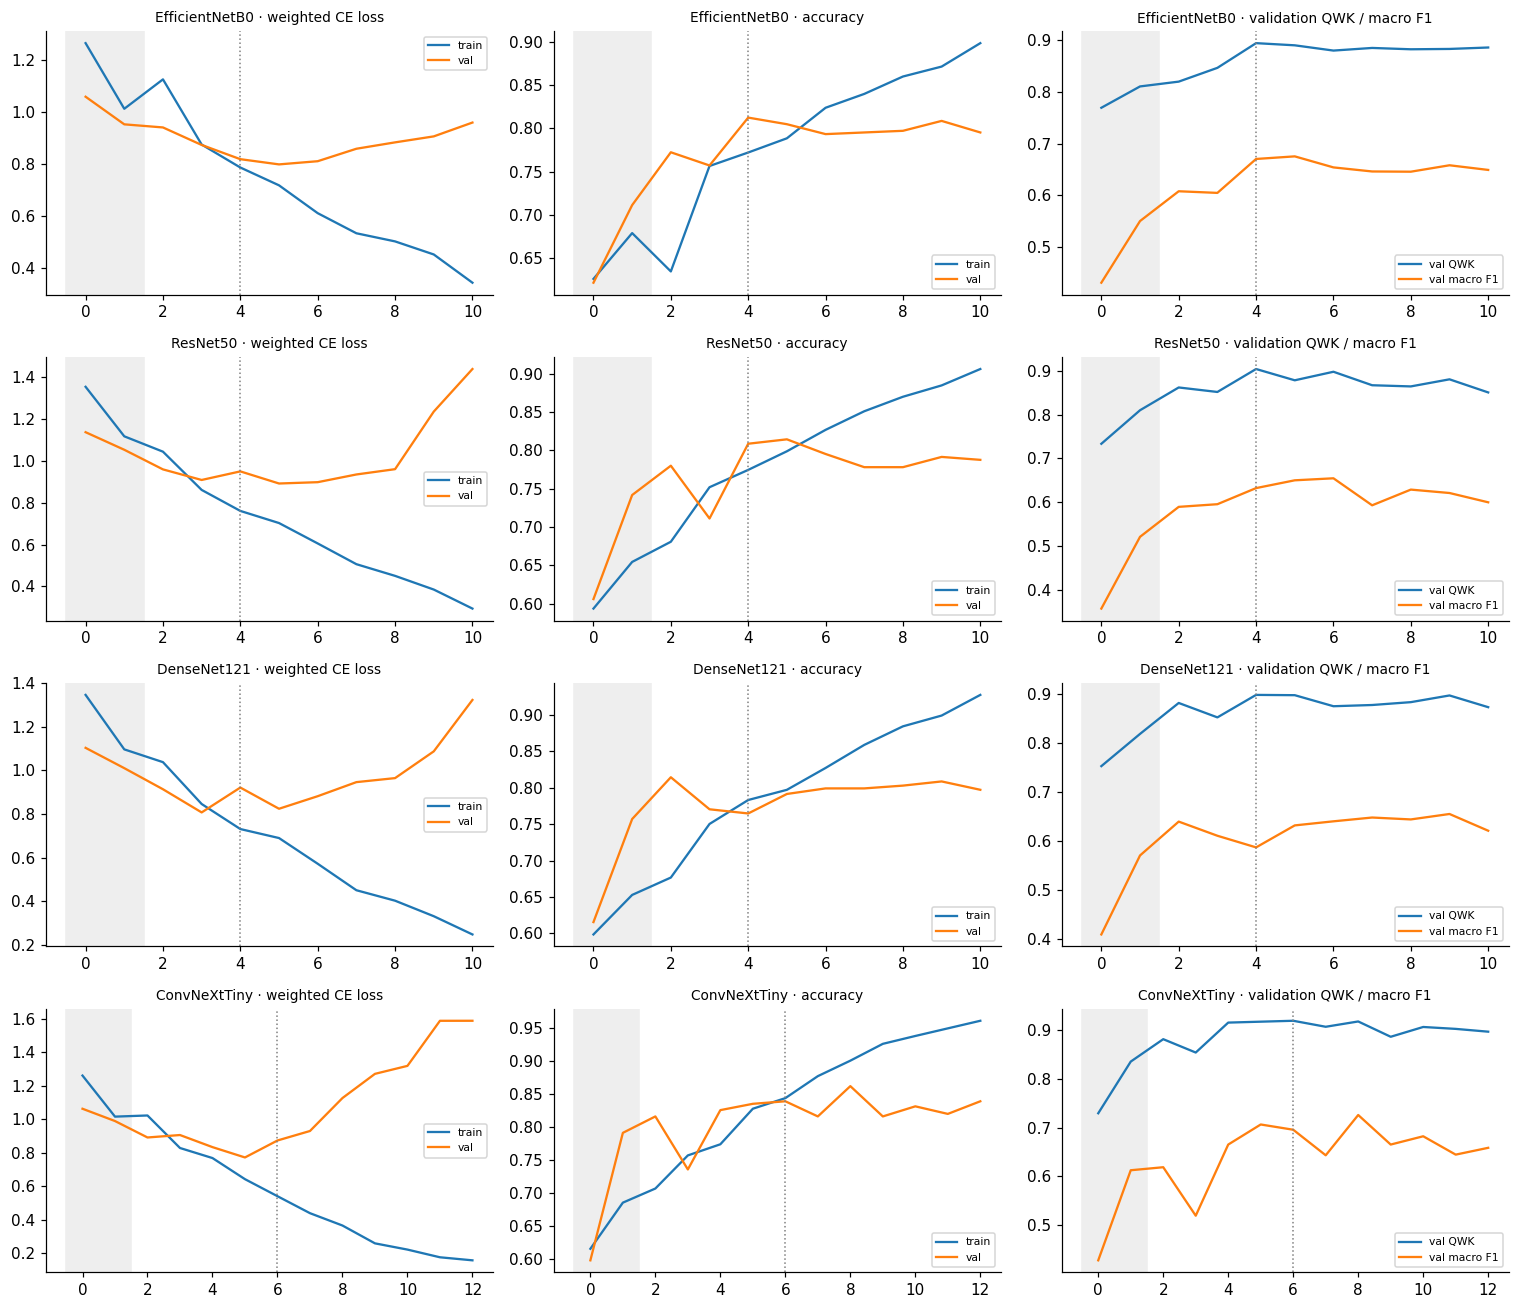

Grey band = frozen-backbone warm-up; dotted line = selected (best-validation) epoch.


In [23]:
def plot_history(arch_runs, fname):
    fig, axes = plt.subplots(len(arch_runs), 3, figsize=(14, 3.0 * len(arch_runs)), squeeze=False)
    for r, (name, s) in enumerate(arch_runs.items()):
        h = pd.read_csv(Path(s['run_dir']) / 'history.csv')
        axes[r, 0].plot(h.epoch, h.train_loss, label='train'); axes[r, 0].plot(h.epoch, h.val_loss, label='val')
        axes[r, 1].plot(h.epoch, h.train_acc, label='train'); axes[r, 1].plot(h.epoch, h.val_acc, label='val')
        axes[r, 2].plot(h.epoch, h.val_qwk, label='val QWK'); axes[r, 2].plot(h.epoch, h.val_macro_f1, label='val macro F1')
        for a, t in zip(axes[r], ('weighted CE loss', 'accuracy', 'validation QWK / macro F1')):
            a.axvline(s['best_epoch'], color='grey', ls=':', lw=1); a.set_title(f'{name} · {t}', fontsize=9); a.legend(fontsize=7)
            a.axvspan(-0.5, PROTOCOL['warmup_frozen_epochs'] - 0.5, color='#eee')
    plt.tight_layout(); plt.savefig(FIG_DIR / fname, bbox_inches='tight'); plt.show()

plot_history(MAIN_RUNS, 'training_curves_main.png')
print('Grey band = frozen-backbone warm-up; dotted line = selected (best-validation) epoch.')

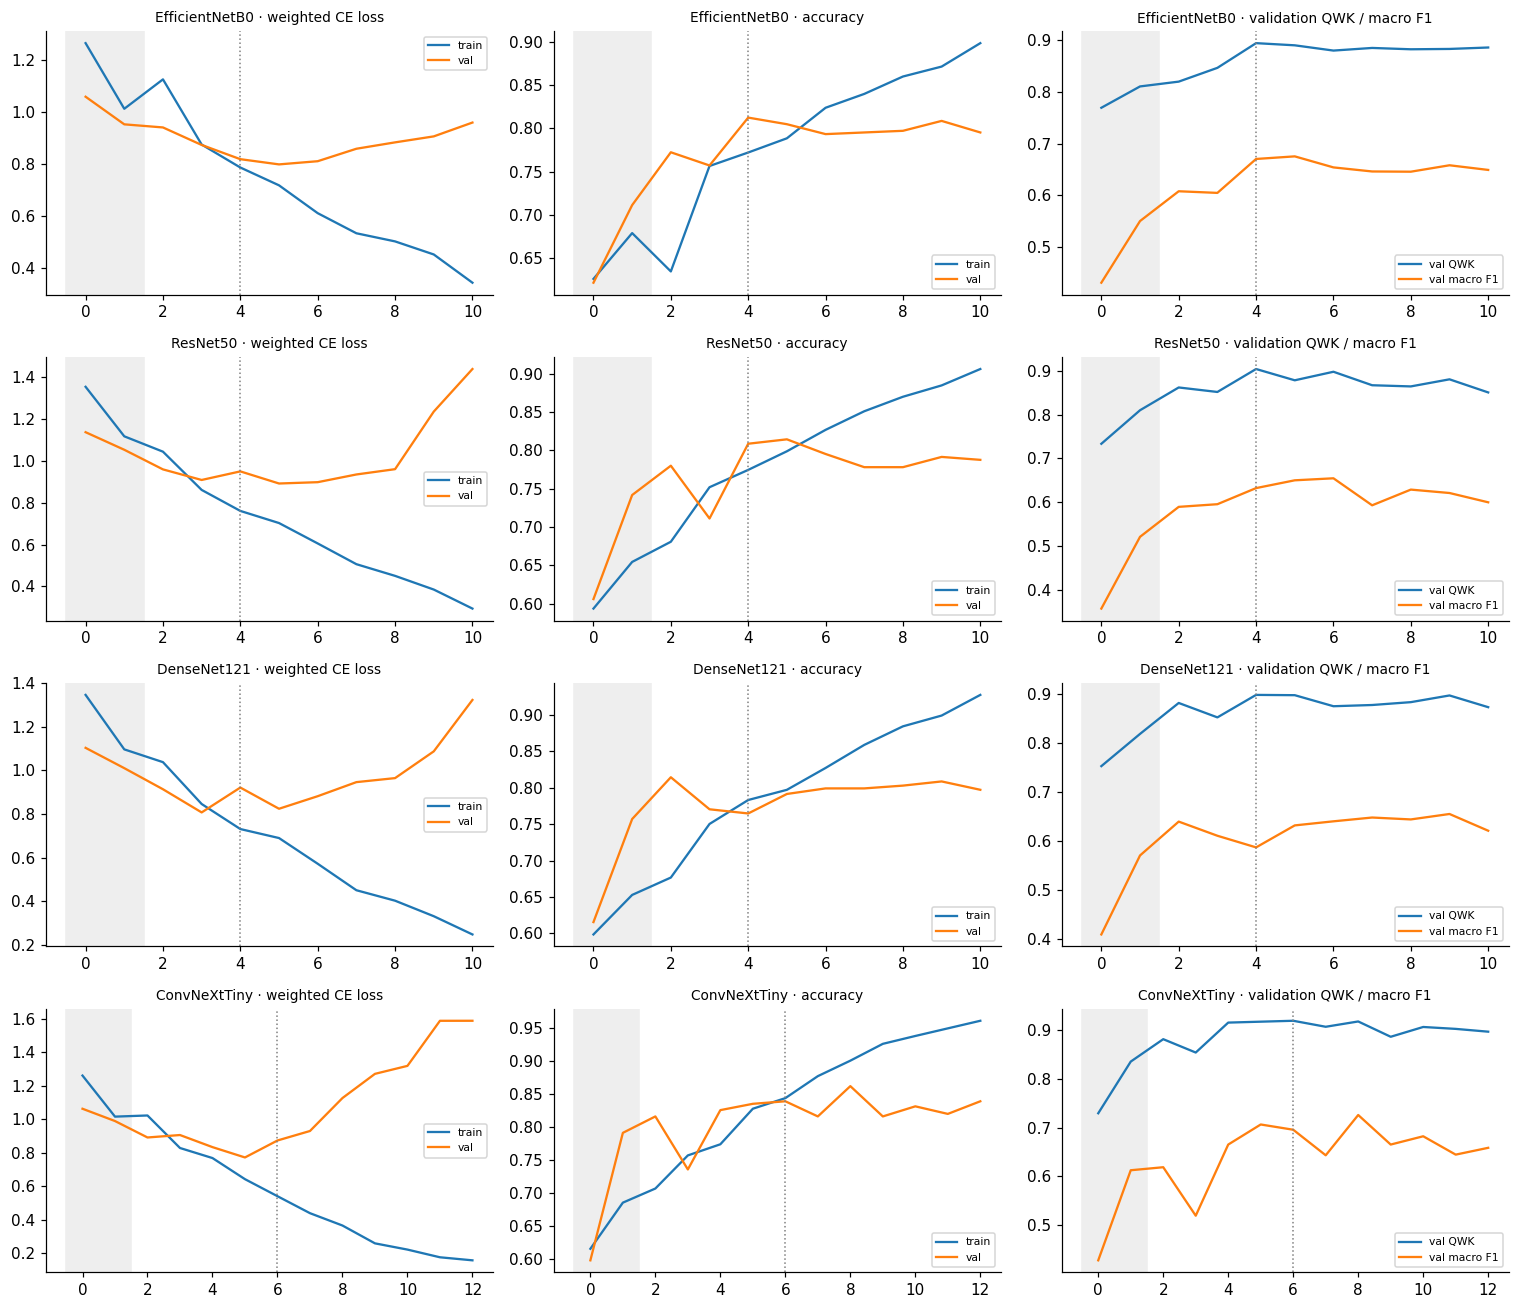

Grey band = frozen-backbone warm-up; dotted line = selected (best-validation) epoch.


In [24]:
def plot_history(arch_runs, fname):
    fig, axes = plt.subplots(len(arch_runs), 3, figsize=(14, 3.0 * len(arch_runs)), squeeze=False)
    for r, (name, s) in enumerate(arch_runs.items()):
        h = pd.read_csv(Path(s['run_dir']) / 'history.csv')
        axes[r, 0].plot(h.epoch, h.train_loss, label='train'); axes[r, 0].plot(h.epoch, h.val_loss, label='val')
        axes[r, 1].plot(h.epoch, h.train_acc, label='train'); axes[r, 1].plot(h.epoch, h.val_acc, label='val')
        axes[r, 2].plot(h.epoch, h.val_qwk, label='val QWK'); axes[r, 2].plot(h.epoch, h.val_macro_f1, label='val macro F1')
        for a, t in zip(axes[r], ('weighted CE loss', 'accuracy', 'validation QWK / macro F1')):
            a.axvline(s['best_epoch'], color='grey', ls=':', lw=1); a.set_title(f'{name} · {t}', fontsize=9); a.legend(fontsize=7)
            a.axvspan(-0.5, PROTOCOL['warmup_frozen_epochs'] - 0.5, color='#eee')
    plt.tight_layout(); plt.savefig(FIG_DIR / fname, bbox_inches='tight'); plt.show()

plot_history(MAIN_RUNS, 'training_curves_main.png')
print('Grey band = frozen-backbone warm-up; dotted line = selected (best-validation) epoch.')

In [25]:
sel_df = pd.DataFrame(MAIN_RUNS.values())
sel_df['params'] = sel_df.architecture.map(arch_table[arch_table.attention == 'cbam'].set_index('architecture').params_total_M)
sel_df['qwk_r'] = sel_df.val_qwk.round(3)
sel_df = sel_df.sort_values(['qwk_r', 'val_macro_f1', 'params'], ascending=[False, False, True])
SELECTED_ARCH = sel_df.iloc[0].architecture
selection_file = EXP_DIR / 'selection.json'
if selection_file.exists() and not RUN_OPTIONS['force_retrain']:
    prev = json.loads(selection_file.read_text())
    assert prev['selected_architecture'] == SELECTED_ARCH, 'Selection changed since the frozen decision; investigate.'
else:
    save_json(dict(selected_architecture=SELECTED_ARCH, criterion=f'max validation {PRIMARY}; tie-break macro F1, params',
                   validation_ranking=sel_df[['architecture', 'val_qwk', 'val_macro_f1', 'val_accuracy']].to_dict('records'),
                   decided_at=time.strftime('%Y-%m-%d %H:%M:%S'), test_set_used=False), selection_file)
display(sel_df[['architecture', 'val_qwk', 'val_macro_f1', 'val_accuracy', 'params']].round(4).reset_index(drop=True))
print(f'Selected architecture for {EXPERIMENT_ID}: {SELECTED_ARCH} (validation-based)')

,architecture,val_qwk,val_macro_f1,val_accuracy,params
0,ConvNeXtTiny,0.9189,0.6956,0.8394,27.8978
1,ResNet50,0.9038,0.6324,0.8088,24.0427
2,DenseNet121,0.8980,0.5866,0.7648,7.0902
3,EfficientNetB0,0.8948,0.6702,0.8126,4.2189


Selected architecture for 03_Green_Channel: ConvNeXtTiny (validation-based)



### EfficientNetB0 (CBAM) — test set


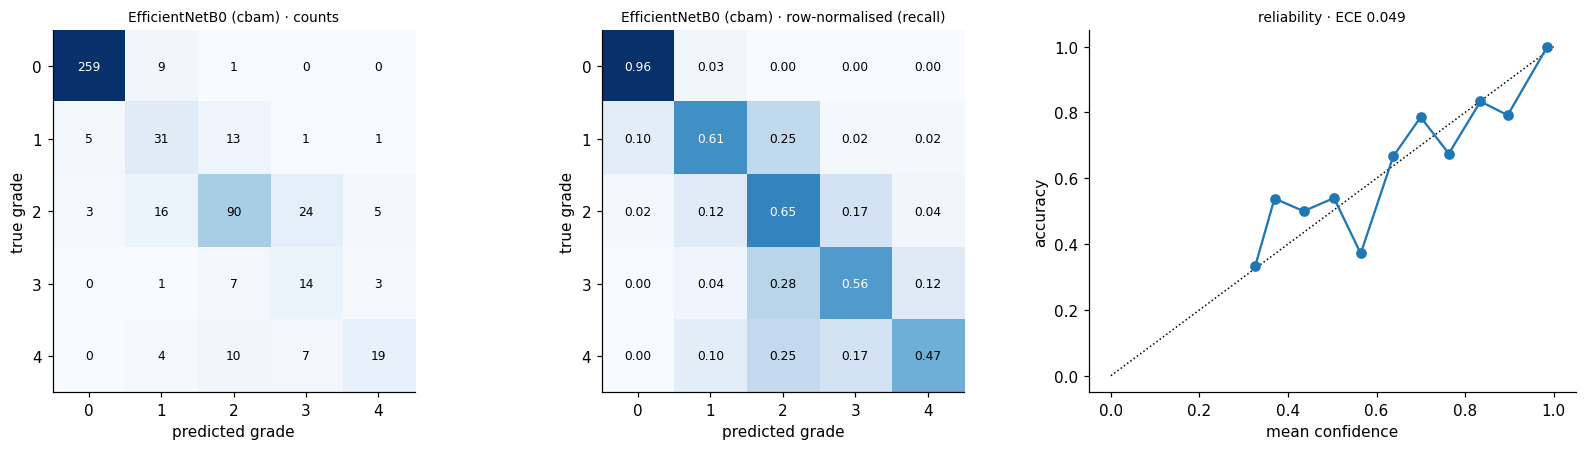

                  precision    recall  f1-score   support

           No DR     0.9700    0.9628    0.9664       269
         Mild DR     0.5082    0.6078    0.5536        51
     Moderate DR     0.7438    0.6522    0.6950       138
       Severe DR     0.3043    0.5600    0.3944        25
Proliferative DR     0.6786    0.4750    0.5588        40

        accuracy                         0.7897       523
       macro avg     0.6410    0.6516    0.6336       523
    weighted avg     0.8112    0.7897    0.7960       523


### ResNet50 (CBAM) — test set


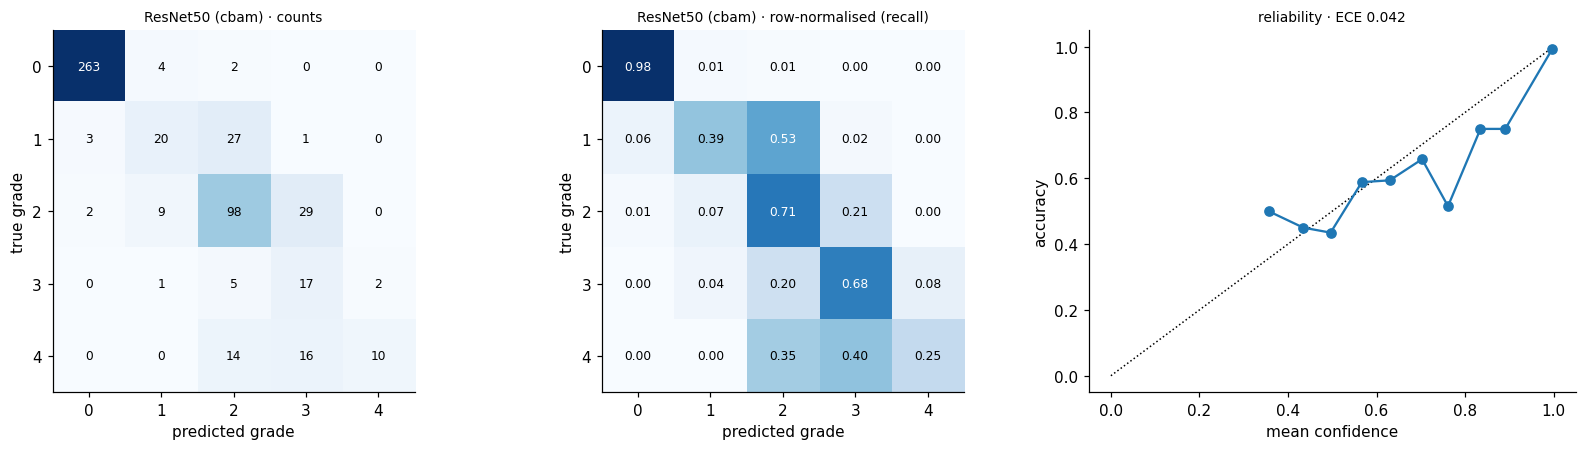

                  precision    recall  f1-score   support

           No DR     0.9813    0.9777    0.9795       269
         Mild DR     0.5882    0.3922    0.4706        51
     Moderate DR     0.6712    0.7101    0.6901       138
       Severe DR     0.2698    0.6800    0.3864        25
Proliferative DR     0.8333    0.2500    0.3846        40

        accuracy                         0.7801       523
       macro avg     0.6688    0.6020    0.5822       523
    weighted avg     0.8159    0.7801    0.7797       523


### DenseNet121 (CBAM) — test set


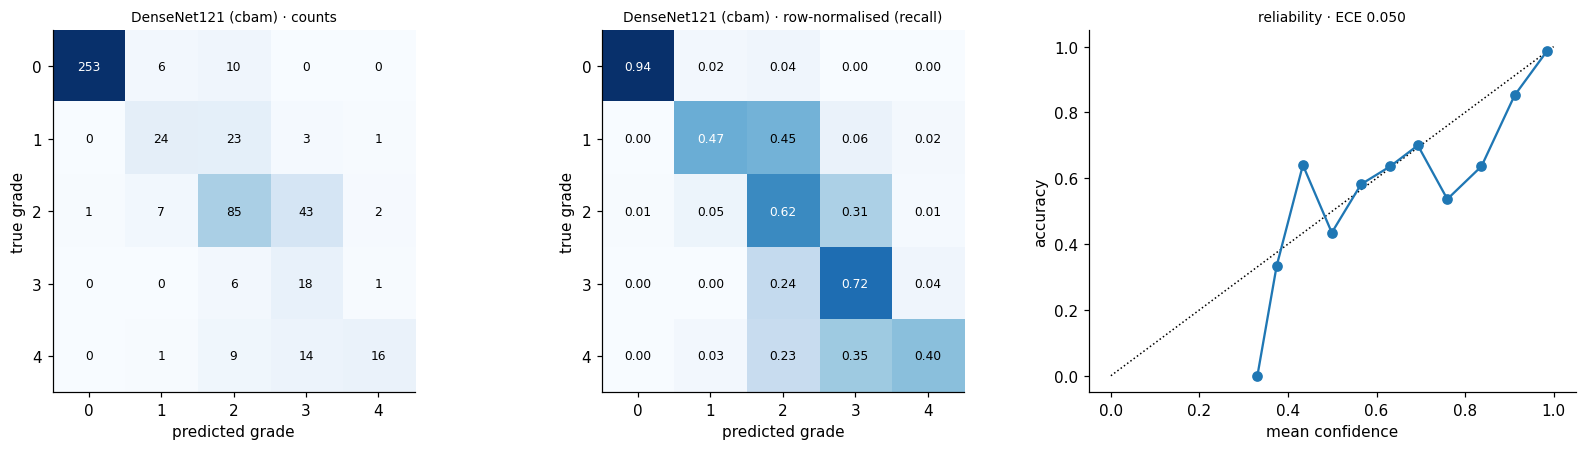

                  precision    recall  f1-score   support

           No DR     0.9961    0.9405    0.9675       269
         Mild DR     0.6316    0.4706    0.5393        51
     Moderate DR     0.6391    0.6159    0.6273       138
       Severe DR     0.2308    0.7200    0.3495        25
Proliferative DR     0.8000    0.4000    0.5333        40

        accuracy                         0.7572       523
       macro avg     0.6595    0.6294    0.6034       523
    weighted avg     0.8148    0.7572    0.7732       523


### ConvNeXtTiny (CBAM) — test set


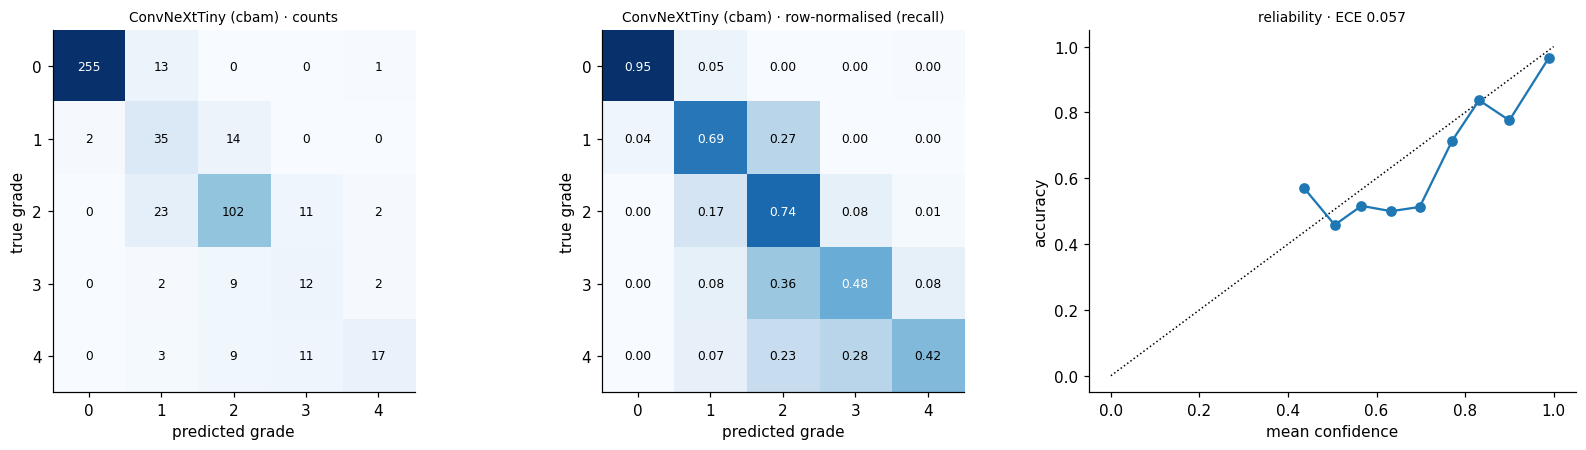

                  precision    recall  f1-score   support

           No DR     0.9922    0.9480    0.9696       269
         Mild DR     0.4605    0.6863    0.5512        51
     Moderate DR     0.7612    0.7391    0.7500       138
       Severe DR     0.3529    0.4800    0.4068        25
Proliferative DR     0.7727    0.4250    0.5484        40

        accuracy                         0.8050       523
       macro avg     0.6679    0.6557    0.6452       523
    weighted avg     0.8321    0.8050    0.8117       523



**Aggregate test metrics (all four architectures, CBAM, seed 42)**

,selected,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,qwk,roc_auc_ovr_macro,ece
EfficientNetB0,False,0.7897,0.6516,0.6410,0.6516,0.6336,0.7960,0.8737,0.9290,0.0490
ResNet50,False,0.7801,0.6020,0.6688,0.6020,0.5822,0.7797,0.8930,0.9293,0.0416
DenseNet121,False,0.7572,0.6294,0.6595,0.6294,0.6034,0.7732,0.8741,0.9165,0.0495
ConvNeXtTiny,True,0.8050,0.6557,0.6679,0.6557,0.6452,0.8117,0.8868,0.9359,0.0571


**Per-grade test metrics**

sensitivity                                               f1                                    
architecture       ConvNeXtTiny DenseNet121 EfficientNetB0 ResNet50 ConvNeXtTiny DenseNet121 EfficientNetB0 ResNet50
grade                                                                                                               
0 No DR                   0.948       0.941          0.963    0.978        0.970       0.967          0.966    0.980
1 Mild DR                 0.686       0.471          0.608    0.392        0.551       0.539          0.554    0.471
2 Moderate DR             0.739       0.616          0.652    0.710        0.750       0.627          0.695    0.690
3 Severe DR               0.480       0.720          0.560    0.680        0.407       0.350          0.394    0.386
4 Proliferative DR        0.425       0.400          0.475    0.250        0.548       0.533          0.559    0.385

In [26]:
def evaluate_run(summary):
    rdir = Path(summary['run_dir'])
    model, cfg = load_dr_model(rdir, device=DEVICE)
    prob, y, _ = predict(model, make_loader('test', False, 0))
    met = MT.compute_metrics(y, prob, GRADE_NAMES)
    pred_df = pd.DataFrame({'image_id': manifest.image_id.values[IDX['test']], 'label': y, 'pred': prob.argmax(1),
                            'group': GROUPS_TEST, **{f'p{k}': prob[:, k] for k in range(5)}})
    pred_df.to_csv(rdir / 'test_predictions.csv', index=False)
    save_json(met, rdir / 'test_metrics.json')
    (rdir / 'classification_report.txt').write_text(met['classification_report'])
    cm = np.array(met['confusion_matrix'])
    pd.DataFrame(cm, index=[f'true {k}' for k in range(5)], columns=[f'pred {k}' for k in range(5)]).to_csv(rdir / 'confusion_matrix.csv')
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
    for ax, mat, title, fmt in ((axes[0], cm, 'counts', 'd'),
                                (axes[1], cm / cm.sum(1, keepdims=True).clip(1), 'row-normalised (recall)', '.2f')):
        ax.imshow(mat, cmap='Blues')
        for i in range(5):
            for j in range(5):
                ax.text(j, i, format(mat[i, j], fmt), ha='center', va='center', fontsize=8,
                        color='white' if mat[i, j] > mat.max() / 2 else 'black')
        ax.set_xticks(range(5)); ax.set_yticks(range(5)); ax.set_xlabel('predicted grade'); ax.set_ylabel('true grade')
        ax.set_title(f"{summary['architecture']} ({summary['attention']}) · {title}", fontsize=9)
    rel = np.array(met['reliability']) if met['reliability'] else np.zeros((0, 4))
    axes[2].plot([0, 1], [0, 1], 'k:', lw=1)
    if len(rel): axes[2].plot(rel[:, 1], rel[:, 2], 'o-')
    axes[2].set_xlabel('mean confidence'); axes[2].set_ylabel('accuracy'); axes[2].set_title(f"reliability · ECE {met['ece']:.3f}", fontsize=9)
    plt.tight_layout(); plt.savefig(rdir / 'confusion_matrix.png', bbox_inches='tight'); plt.show()
    del model
    return met, pred_df

TEST = {}
for arch in PROTOCOL['architectures']:
    print(f'\n### {arch} (CBAM) — test set')
    TEST[arch] = evaluate_run(MAIN_RUNS[arch])
    print(TEST[arch][0]['classification_report'])

agg_cols = ['accuracy', 'balanced_accuracy', 'macro_precision', 'macro_recall', 'macro_f1', 'weighted_f1', 'qwk', 'roc_auc_ovr_macro', 'ece']
agg = pd.DataFrame({a: {c: TEST[a][0][c] for c in agg_cols} for a in TEST}).T
agg.insert(0, 'selected', [a == SELECTED_ARCH for a in agg.index])
display(Markdown('**Aggregate test metrics (all four architectures, CBAM, seed 42)**')); display(agg.round(4))
per_rows = []
for a in TEST:
    for k, v in TEST[a][0]['per_class'].items():
        per_rows.append(dict(architecture=a, grade=f"{k} {v['grade']}", sensitivity=v['recall_sensitivity'],
                             specificity=v['specificity'], precision=v['precision'], f1=v['f1'], auc=v['roc_auc_ovr'], support=v['support']))
per_df = pd.DataFrame(per_rows)
display(Markdown('**Per-grade test metrics**')); display(per_df.pivot(index='grade', columns='architecture', values=['sensitivity', 'f1']).round(3))
agg.to_csv(EXP_DIR / 'test_metrics_main.csv'); per_df.to_csv(EXP_DIR / 'test_per_class_main.csv', index=False)


=== ablation | ConvNeXtTiny | none | seed 42 ===
[skip] 03_Green_Channel/ConvNeXtTiny/noattn_seed42 already complete


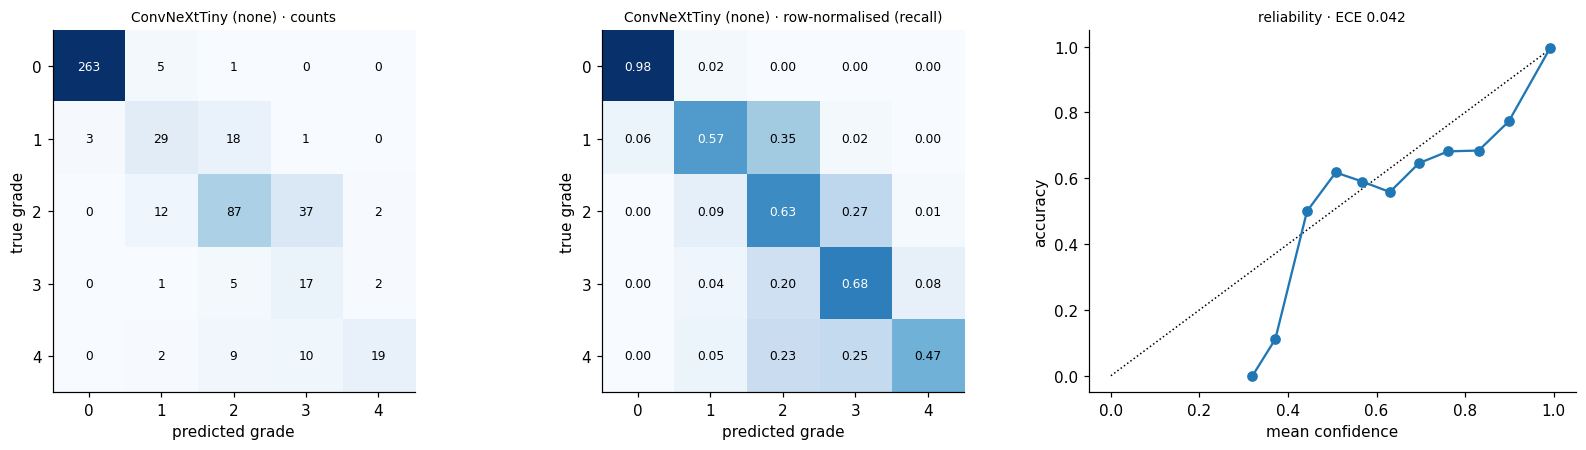


=== ablation | ConvNeXtTiny | cbam | seed 43 ===
[skip] 03_Green_Channel/ConvNeXtTiny/cbam_seed43 already complete


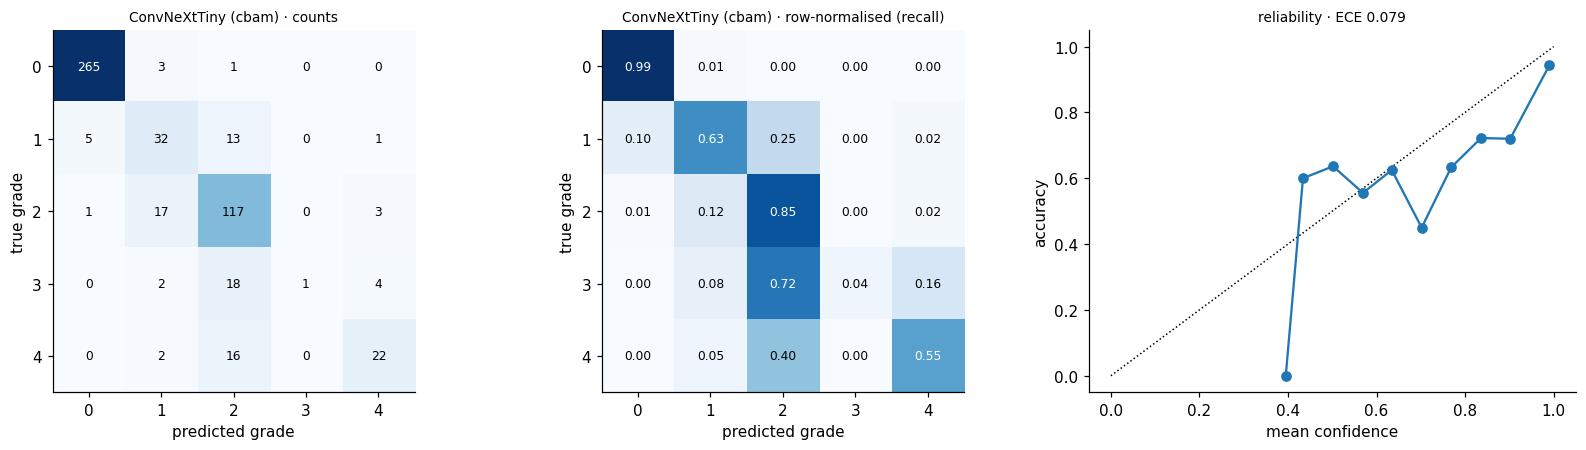


=== ablation | ConvNeXtTiny | none | seed 43 ===
[skip] 03_Green_Channel/ConvNeXtTiny/noattn_seed43 already complete


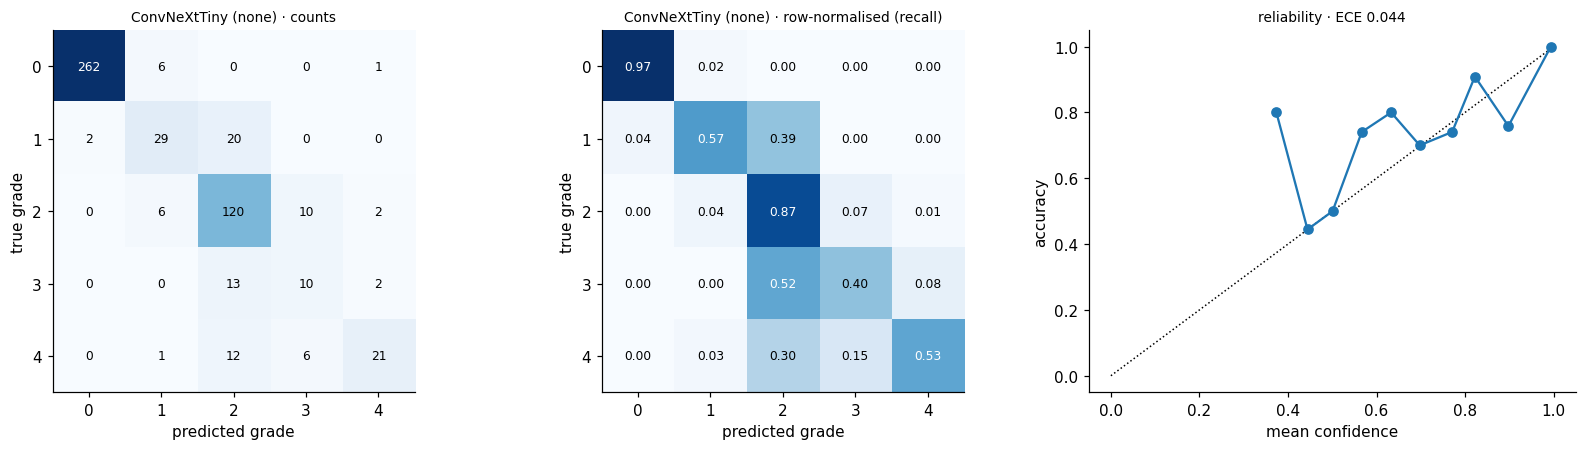


=== ablation | ConvNeXtTiny | cbam | seed 44 ===
[skip] 03_Green_Channel/ConvNeXtTiny/cbam_seed44 already complete


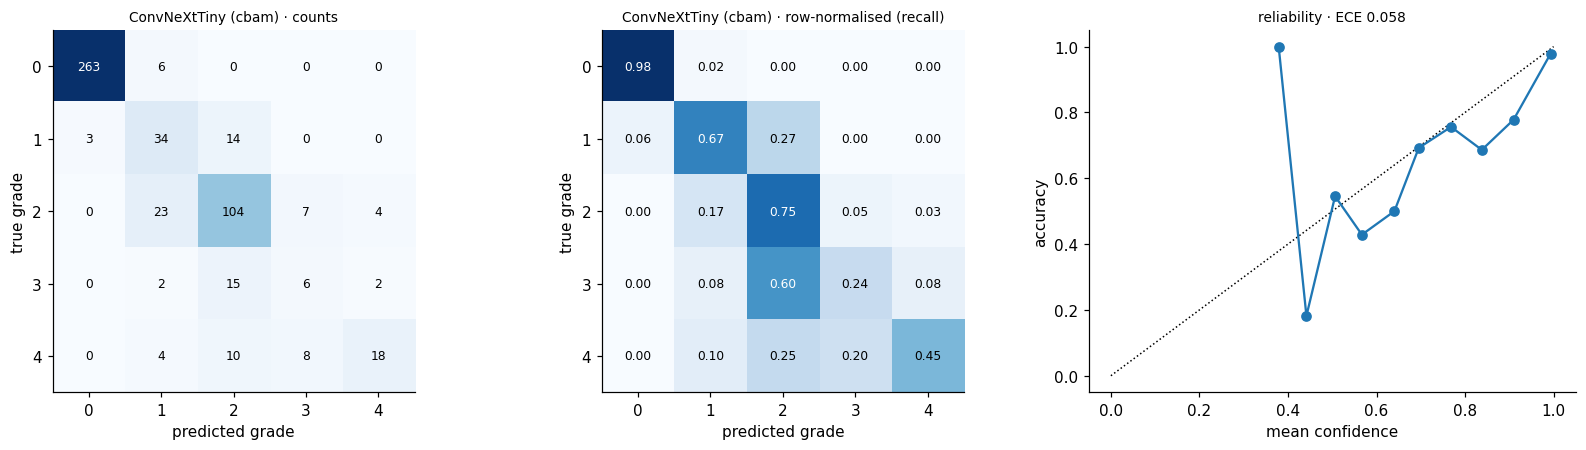


=== ablation | ConvNeXtTiny | none | seed 44 ===
  ep00 F loss 1.264/1.119 acc 0.607/0.677 vF1 0.466 vQWK 0.708  *best  [0.2 min]
  ep01 F loss 1.035/1.034 acc 0.691/0.748 vF1 0.509 vQWK 0.789  *best  [0.6 min]
  ep02   loss 0.986/0.806 acc 0.715/0.805 vF1 0.633 vQWK 0.908  *best  [1.0 min]
  ep03   loss 0.842/0.842 acc 0.759/0.784 vF1 0.615 vQWK 0.883  [1.3 min]
  ep04   loss 0.694/0.834 acc 0.792/0.813 vF1 0.648 vQWK 0.893  [1.7 min]
  ep05   loss 0.594/0.926 acc 0.818/0.826 vF1 0.653 vQWK 0.900  [2.0 min]
  ep06   loss 0.566/0.874 acc 0.846/0.839 vF1 0.686 vQWK 0.915  *best  [2.3 min]
  ep07   loss 0.460/0.871 acc 0.857/0.809 vF1 0.641 vQWK 0.890  [2.6 min]
  ep08   loss 0.331/1.052 acc 0.905/0.828 vF1 0.664 vQWK 0.890  [3.0 min]
  ep09   loss 0.291/1.202 acc 0.914/0.828 vF1 0.669 vQWK 0.893  [3.4 min]
  ep10   loss 0.228/1.240 acc 0.933/0.816 vF1 0.662 vQWK 0.902  [3.8 min]
  ep11   loss 0.158/1.248 acc 0.954/0.820 vF1 0.669 vQWK 0.903  [4.2 min]
  ep12   loss 0.106/1.549 acc 0.96

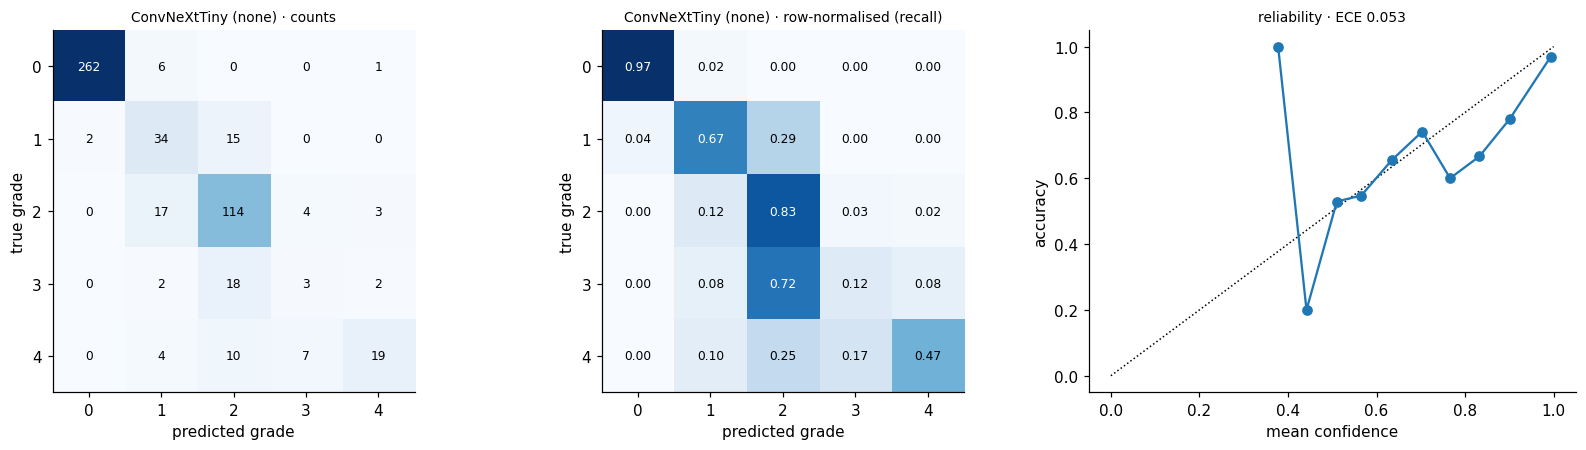

,attention,seed,val_qwk,val_macro_f1,test_qwk,test_macro_f1,test_accuracy,test_balanced_accuracy,best_epoch
0,cbam,42,0.9189,0.6956,0.8868,0.6452,0.8050,0.6557,6
2,cbam,43,0.9028,0.6050,0.8866,0.6115,0.8356,0.6101,6
4,cbam,44,0.9172,0.7050,0.8872,0.6227,0.8126,0.6176,6
1,none,42,0.9198,0.6674,0.9030,0.6437,0.7935,0.6664,4
3,none,43,0.9131,0.6722,0.9104,0.6855,0.8451,0.6674,4
5,none,44,0.9147,0.6863,0.8834,0.6182,0.8260,0.6123,6


**Mean ± SD across 3 seeds (ConvNeXtTiny)**

val_qwk         val_macro_f1         test_qwk         test_macro_f1         test_accuracy        
             mean     std         mean     std     mean     std          mean     std          mean     std
attention                                                                                                  
cbam       0.9129  0.0089       0.6685  0.0552   0.8869  0.0003        0.6264  0.0172        0.8177  0.0159
none       0.9159  0.0035       0.6753  0.0098   0.8989  0.0140        0.6491  0.0340        0.8215  0.0261

In [27]:
ABL = {}
if RUN_OPTIONS['run_ablation']:
    for seed in PROTOCOL['ablation_seeds']:
        for att in ('cbam', 'none'):
            if att == 'cbam' and seed == PROTOCOL['seed_main']:
                ABL[(att, seed)] = (MAIN_RUNS[SELECTED_ARCH], TEST[SELECTED_ARCH]); continue
            print(f'\n=== ablation | {SELECTED_ARCH} | {att} | seed {seed} ===')
            s = train_run(SELECTED_ARCH, att, seed)
            ABL[(att, seed)] = (s, evaluate_run(s))
    abl_rows = [dict(attention=att, seed=seed, val_qwk=s['val_qwk'], val_macro_f1=s['val_macro_f1'],
                     test_qwk=m[0]['qwk'], test_macro_f1=m[0]['macro_f1'], test_accuracy=m[0]['accuracy'],
                     test_balanced_accuracy=m[0]['balanced_accuracy'], best_epoch=s['best_epoch'])
                for (att, seed), (s, m) in ABL.items()]
    abl_df = pd.DataFrame(abl_rows).sort_values(['attention', 'seed'])
    display(abl_df.round(4))
    abl_summary = abl_df.groupby('attention')[['val_qwk', 'val_macro_f1', 'test_qwk', 'test_macro_f1', 'test_accuracy']].agg(['mean', 'std'])
    display(Markdown(f'**Mean ± SD across {len(PROTOCOL["ablation_seeds"])} seeds ({SELECTED_ARCH})**')); display(abl_summary.round(4))
    abl_df.to_csv(EXP_DIR / 'attention_ablation_runs.csv', index=False)
else:
    abl_df = None
    print('Ablation skipped by configuration (limitation: no seed variance / attention evidence).')

In [28]:
B, NP, ALPHA = PROTOCOL['n_bootstrap'], PROTOCOL['n_permutations'], PROTOCOL['alpha']
ci_rows = []
for a, (met, pdf) in TEST.items():
    ci = MT.bootstrap_ci(pdf.label.values, pdf.pred.values, groups=pdf.group.values, n_boot=B, alpha=ALPHA, seed=1)
    for k, v in ci.items():
        ci_rows.append(dict(architecture=a, metric=k, estimate=v['estimate'], ci_low=v['ci_low'], ci_high=v['ci_high']))
ci_df = pd.DataFrame(ci_rows)
ci_df['formatted'] = ci_df.apply(lambda r: f"{r.estimate:.3f} [{r.ci_low:.3f}, {r.ci_high:.3f}]", axis=1)
display(Markdown('**Test metrics with 95% bootstrap CIs**'))
display(ci_df.pivot(index='architecture', columns='metric', values='formatted'))
ci_df.to_csv(EXP_DIR / 'test_bootstrap_ci_main.csv', index=False)

ref = TEST[SELECTED_ARCH][1]
cmp_rows = []
for metric in ('qwk', 'macro_f1'):
    rows = []
    for a in TEST:
        if a == SELECTED_ARCH: continue
        other = TEST[a][1]
        assert (other.image_id.values == ref.image_id.values).all()
        pt = MT.paired_permutation_test(ref.label.values, ref.pred.values, other.pred.values, metric, ref.group.values, NP, seed=2)
        bd = MT.paired_bootstrap_diff(ref.label.values, ref.pred.values, other.pred.values, metric, ref.group.values, B, ALPHA, seed=3)
        rows.append(dict(metric=metric, comparison=f'{SELECTED_ARCH} − {a}', diff=pt['diff'], ci_low=bd['ci_low'], ci_high=bd['ci_high'], p_raw=pt['p_value']))
    adj = MT.holm_correction([r['p_raw'] for r in rows])
    for r, p in zip(rows, adj): r['p_holm'] = p
    cmp_rows += rows
cmp_df = pd.DataFrame(cmp_rows)
display(Markdown('**Exploratory paired comparisons on the test set (selected vs others)**')); display(cmp_df.round(4))
cmp_df.to_csv(EXP_DIR / 'architecture_comparisons.csv', index=False)

abl_tests = None
if abl_df is not None:
    rows = []
    for seed in PROTOCOL['ablation_seeds']:
        pa, pb = ABL[('cbam', seed)][1][1], ABL[('none', seed)][1][1]
        for metric in ('qwk', 'macro_f1'):
            pt = MT.paired_permutation_test(pa.label.values, pa.pred.values, pb.pred.values, metric, pa.group.values, NP, seed=4)
            bd = MT.paired_bootstrap_diff(pa.label.values, pa.pred.values, pb.pred.values, metric, pa.group.values, B, ALPHA, seed=5)
            rows.append(dict(seed=seed, metric=metric, diff_cbam_minus_noattn=pt['diff'], ci_low=bd['ci_low'], ci_high=bd['ci_high'], p_value=pt['p_value']))
    abl_tests = pd.DataFrame(rows)
    display(Markdown('**Attention ablation: Δ = CBAM − NoAttn per seed (test set)**')); display(abl_tests.round(4))
    for metric in ('qwk', 'macro_f1'):
        d = abl_tests[abl_tests.metric == metric].diff_cbam_minus_noattn
        print(f"{metric}: mean Δ {d.mean():+.4f} (SD {d.std():.4f}); positive in {(d > 0).sum()}/{len(d)} seeds")
    vd = abl_df.pivot(index='seed', columns='attention', values='val_qwk')
    print(f"validation QWK Δ per seed: {(vd['cbam'] - vd['none']).round(4).to_dict()}")
    abl_tests.to_csv(EXP_DIR / 'attention_ablation_tests.csv', index=False)

**Test metrics with 95% bootstrap CIs**

metric,accuracy,balanced_accuracy,macro_f1,qwk
architecture,,,,
ConvNeXtTiny,"0.805 [0.769, 0.838]","0.656 [0.595, 0.712]","0.645 [0.584, 0.698]","0.887 [0.851, 0.916]"
DenseNet121,"0.757 [0.721, 0.795]","0.629 [0.570, 0.688]","0.603 [0.546, 0.655]","0.874 [0.847, 0.900]"
EfficientNetB0,"0.790 [0.755, 0.826]","0.652 [0.591, 0.711]","0.634 [0.578, 0.686]","0.874 [0.841, 0.904]"
ResNet50,"0.780 [0.746, 0.815]","0.602 [0.546, 0.658]","0.582 [0.524, 0.641]","0.893 [0.870, 0.913]"


**Exploratory paired comparisons on the test set (selected vs others)**

,metric,comparison,diff,ci_low,ci_high,p_raw,p_holm
0,qwk,ConvNeXtTiny − EfficientNetB0,0.0131,-0.0155,0.0411,0.3813,1.0000
1,qwk,ConvNeXtTiny − ResNet50,-0.0062,-0.0319,0.0197,0.6541,1.0000
2,qwk,ConvNeXtTiny − DenseNet121,0.0127,-0.0145,0.0398,0.3713,1.0000
3,macro_f1,ConvNeXtTiny − EfficientNetB0,0.0116,-0.0412,0.0602,0.6699,0.6699
4,macro_f1,ConvNeXtTiny − ResNet50,0.0629,0.0025,0.1234,0.0494,0.1482
5,macro_f1,ConvNeXtTiny − DenseNet121,0.0418,-0.0097,0.0957,0.1160,0.2320


**Attention ablation: Δ = CBAM − NoAttn per seed (test set)**

,seed,metric,diff_cbam_minus_noattn,ci_low,ci_high,p_value
0,42,qwk,-0.0162,-0.0403,0.0048,0.1538
1,42,macro_f1,0.0015,-0.0422,0.0486,0.9480
2,43,qwk,-0.0238,-0.0482,0.0024,0.0610
3,43,macro_f1,-0.0740,-0.1234,-0.0177,0.0268
4,44,qwk,0.0037,-0.0148,0.0296,0.8000
5,44,macro_f1,0.0045,-0.0308,0.0424,0.8208


qwk: mean Δ -0.0121 (SD 0.0142); positive in 1/3 seeds
macro_f1: mean Δ -0.0227 (SD 0.0445); positive in 2/3 seeds
validation QWK Δ per seed: {42: -0.0009, 43: -0.0103, 44: 0.0025}


In [29]:
def measure_latency(model, bs=1, iters=30, warm=10):
    x = torch.randn(bs, 3, IMG, IMG, device=DEVICE)
    model.eval()
    with torch.no_grad(), torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
        for _ in range(warm): model(x)
        if DEVICE.type == 'cuda': torch.cuda.synchronize()
        t = time.perf_counter()
        for _ in range(iters): model(x)
        if DEVICE.type == 'cuda': torch.cuda.synchronize()
    return (time.perf_counter() - t) / iters

eff_rows = []
for arch in PROTOCOL['architectures']:
    s = MAIN_RUNS[arch]
    model, _ = load_dr_model(s['run_dir'], device=DEVICE)
    n_iter = 5 if SMOKE_TEST else 30
    lat1 = measure_latency(model, 1, n_iter); latb = measure_latency(model, 32, max(3, n_iter // 3))
    eff_rows.append(dict(architecture=arch, params_M=sum(p.numel() for p in model.parameters()) / 1e6,
                         trainable_params_M=sum(p.numel() for p in model.parameters()) / 1e6,
                         checkpoint_MB=(Path(s['run_dir']) / 'best_model.pt').stat().st_size / 1e6,
                         train_minutes=s['train_seconds'] / 60, epochs=s['epochs_run'],
                         latency_ms_bs1=1000 * lat1, throughput_img_s_bs32=32 / latb, device=ENV['gpu'] or 'cpu',
                         test_qwk=TEST[arch][0]['qwk'], test_macro_f1=TEST[arch][0]['macro_f1']))
    del model
eff_df = pd.DataFrame(eff_rows)
display(eff_df.round(3)); eff_df.to_csv(EXP_DIR / 'efficiency.csv', index=False)
print('All parameters are trainable during full fine-tuning (backbone frozen only for the 2 warm-up epochs).')

,architecture,params_M,trainable_params_M,checkpoint_MB,train_minutes,epochs,latency_ms_bs1,throughput_img_s_bs32,device,test_qwk,test_macro_f1
0,EfficientNetB0,4.219,4.219,17.176,3.298,11,23.979,1355.191,Tesla T4,0.874,0.634
1,ResNet50,24.043,24.043,96.493,3.772,11,8.071,782.154,Tesla T4,0.893,0.582
2,DenseNet121,7.090,7.090,28.972,3.793,11,18.441,631.834,Tesla T4,0.874,0.603
3,ConvNeXtTiny,27.898,27.898,111.660,4.749,13,7.647,650.538,Tesla T4,0.887,0.645


All parameters are trainable during full fine-tuning (backbone frozen only for the 2 warm-up epochs).


In [30]:
PKG = OUTPUT_ROOT / 'inference_package'
(PKG / 'dr_lib').mkdir(parents=True, exist_ok=True)
for p in LIB_DIR.glob('*.py'):
    shutil.copy(p, PKG / 'dr_lib' / p.name)
(PKG / 'example_backend.py').write_text('''"""Minimal FastAPI example: POST an image, receive grade + probabilities.
pip install fastapi uvicorn python-multipart torch torchvision opencv-python-headless PyWavelets
uvicorn example_backend:app --host 0.0.0.0 --port 8000
"""
import os
from fastapi import FastAPI, File, UploadFile
from dr_lib.inference import load_dr_model, predict_fundus

RUN_DIR = os.environ.get("DR_RUN_DIR", "path/to/DR_Grading_Research/05_Baseline/ResNet50/cbam_seed42")
model, cfg = load_dr_model(RUN_DIR, device="cpu")
app = FastAPI()

@app.post("/predict")
async def predict(file: UploadFile = File(...)):
    return predict_fundus(await file.read(), model, cfg)
''')

README_RUN = '''# {exp} · {arch} · {att} · seed {seed}
Diabetic retinopathy 5-grade classifier (research prototype — not for clinical use).

| item | value |
|---|---|
| preprocessing | {method} {params} |
| input | original fundus photo → crop/pad/resize {S} → {method} → resize {img} → ImageNet normalisation |
| best epoch | {best_epoch} |
| validation QWK / macro F1 | {vq:.4f} / {vf:.4f} |
| test QWK / macro F1 / accuracy | {tq:.4f} / {tf:.4f} / {ta:.4f} |

Files: `best_model.pt` (PyTorch state_dict), `model_config.json`, `history.csv`, `val_metrics.json`,
`test_metrics.json`, `test_predictions.csv`, `classification_report.txt`, `confusion_matrix.(png|csv)`.

```python
import sys; sys.path.insert(0, "<DR_Grading_Research>/inference_package")
from dr_lib.inference import load_dr_model, predict_fundus
model, cfg = load_dr_model("<this folder>", device="cpu")
print(predict_fundus("fundus.png", model, cfg))
```
'''
all_runs = [(MAIN_RUNS[a], TEST[a]) for a in TEST] + [v for (att, sd), v in ABL.items() if not (att == 'cbam' and sd == PROTOCOL['seed_main'])]
for s, (met, _) in all_runs:
    Path(s['run_dir'], 'README.md').write_text(README_RUN.format(
        exp=EXPERIMENT_ID, arch=s['architecture'], att=s['attention'], seed=s['seed'], method=PREPROCESSING_METHOD,
        params=json.dumps(METHOD_PARAMS), S=S, img=IMG, best_epoch=s['best_epoch'], vq=s['val_qwk'], vf=s['val_macro_f1'],
        tq=met['qwk'], tf=met['macro_f1'], ta=met['accuracy']))

# round-trip check on raw files
sel_run = MAIN_RUNS[SELECTED_ARCH]
model_cpu, cfg_cpu = load_dr_model(sel_run['run_dir'], device='cpu')
ref_pred = TEST[SELECTED_ARCH][1].head(5)
path_map = labels_df.set_index('image_id').path
diffs, agree = [], 0
for r in ref_pred.itertuples():
    out = predict_fundus(path_map[r.image_id], model_cpu, cfg_cpu)
    p = np.array(list(out['probabilities'].values()))
    diffs.append(np.abs(p - np.array([getattr(r, f'p{k}') for k in range(5)])).max()); agree += int(out['grade'] == r.pred)
print(f'Round-trip on {len(ref_pred)} raw test images: grade agreement {agree}/{len(ref_pred)}, '
      f'max |Δprob| {max(diffs):.4f} (small differences come from GPU mixed precision vs CPU float32)')
print('Example output:', json.dumps(out, indent=1)[:500])
assert agree >= len(ref_pred) - 1, 'Deployment path disagrees with evaluation path — check preprocessing consistency.'

EXPERIMENT_SUMMARY = dict(
    experiment_id=EXPERIMENT_ID, preprocessing_method=PREPROCESSING_METHOD, preprocessing_params=METHOD_PARAMS,
    protocol_hash=PROTOCOL_HASH, protocol=PROTOCOL, split_sha=SPLIT_SHA, dr_lib_hash=LIB_HASH, smoke_test=SMOKE_TEST,
    selected_architecture=SELECTED_ARCH, selected_run_dir=sel_run['run_dir'],
    main_runs={a: dict(MAIN_RUNS[a], test={c: TEST[a][0][c] for c in agg_cols}) for a in TEST},
    efficiency=eff_df.to_dict('records'), detail_retention=DETAIL_RETENTION,
    ablation=None if abl_df is None else dict(runs=abl_df.to_dict('records'), tests=abl_tests.to_dict('records'),
                                              run_dirs={f'{att}_{sd}': v[0]['run_dir'] for (att, sd), v in ABL.items()}),
    environment=ENV, finished_at=time.strftime('%Y-%m-%d %H:%M:%S'))
save_json(EXPERIMENT_SUMMARY, EXP_DIR / 'experiment_summary.json')
print(f'Saved experiment summary → {EXP_DIR / "experiment_summary.json"}')

Round-trip on 5 raw test images: grade agreement 5/5, max |Δprob| 0.0022 (small differences come from GPU mixed precision vs CPU float32)
Example output: {
 "grade": 0,
 "grade_name": "No DR",
 "probabilities": {
  "No DR": 0.9168065190315247,
  "Mild DR": 0.07724427431821823,
  "Moderate DR": 0.005645682569593191,
  "Severe DR": 1.091174635803327e-05,
  "Proliferative DR": 0.0002926171582657844
 },
 "model": "ConvNeXtTiny (cbam) | preprocessing=green_channel",
 "disclaimer": "Research prototype; not for clinical diagnosis."
}
Saved experiment summary → /content/drive/MyDrive/DR_Grading_Research/03_Green_Channel/experiment_summary.json


In [31]:
sm, sp = TEST[SELECTED_ARCH]
ci_sel = ci_df[ci_df.architecture == SELECTED_ARCH].set_index('metric')
pc = sm['per_class']
weakest = min(pc, key=lambda k: pc[k]['recall_sensitivity'])
strongest = max(pc, key=lambda k: pc[k]['recall_sensitivity'])
lines = [
    f"* Preprocessing: **{PREPROCESSING_METHOD}**; validation-selected architecture: **{SELECTED_ARCH}** "
    f"(validation QWK {MAIN_RUNS[SELECTED_ARCH]['val_qwk']:.3f}).",
    f"* Test QWK {ci_sel.loc['qwk', 'estimate']:.3f} (95% CI {ci_sel.loc['qwk', 'ci_low']:.3f}–{ci_sel.loc['qwk', 'ci_high']:.3f}); "
    f"macro F1 {ci_sel.loc['macro_f1', 'estimate']:.3f} ({ci_sel.loc['macro_f1', 'ci_low']:.3f}–{ci_sel.loc['macro_f1', 'ci_high']:.3f}); "
    f"accuracy {sm['accuracy']:.3f}; balanced accuracy {sm['balanced_accuracy']:.3f}.",
    f"* Highest sensitivity: grade {strongest} ({pc[strongest]['grade']}, {pc[strongest]['recall_sensitivity']:.3f}); "
    f"lowest: grade {weakest} ({pc[weakest]['grade']}, {pc[weakest]['recall_sensitivity']:.3f}, n={pc[weakest]['support']}).",
    f"* Gap between accuracy and macro F1: {sm['accuracy'] - sm['macro_f1']:+.3f} — a large positive gap indicates that "
    "majority-grade performance is masking weaker minority-grade performance.",
    f"* Calibration: ECE {sm['ece']:.3f}.",
]
sig = cmp_df[(cmp_df.metric == 'qwk') & (cmp_df.p_holm < ALPHA)]
lines.append(f"* Exploratory architecture comparisons (QWK, Holm-adjusted): {len(sig)} of {len(cmp_df[cmp_df.metric == 'qwk'])} "
             "differences have p < 0.05." + ('' if len(sig) else ' Architecture differences are not statistically distinguishable on this test set.'))
if abl_tests is not None:
    d = abl_tests[abl_tests.metric == 'qwk'].diff_cbam_minus_noattn
    lines.append(f"* Attention ablation ({SELECTED_ARCH}): mean test ΔQWK (CBAM − NoAttn) {d.mean():+.4f} ± {d.std():.4f} over "
                 f"{len(d)} seeds; positive in {(d > 0).sum()}/{len(d)} seeds. Treat as exploratory.")
lines.append(f"* Detail retention (green-channel Laplacian variance ratio): {DETAIL_RETENTION['laplacian_var_ratio_green_mean']:.3f} "
             "(1.0 = fine structure unchanged; lower = smoothing of fine detail such as microaneurysms).")
if SMOKE_TEST:
    lines.insert(0, '* **SMOKE TEST — numbers below are meaningless.**')
display(Markdown('\n'.join(lines)))

* Preprocessing: **green_channel**; validation-selected architecture: **ConvNeXtTiny** (validation QWK 0.919).
* Test QWK 0.887 (95% CI 0.851–0.916); macro F1 0.645 (0.584–0.698); accuracy 0.805; balanced accuracy 0.656.
* Highest sensitivity: grade 0 (No DR, 0.948); lowest: grade 4 (Proliferative DR, 0.425, n=40).
* Gap between accuracy and macro F1: +0.160 — a large positive gap indicates that majority-grade performance is masking weaker minority-grade performance.
* Calibration: ECE 0.057.
* Exploratory architecture comparisons (QWK, Holm-adjusted): 0 of 3 differences have p < 0.05. Architecture differences are not statistically distinguishable on this test set.
* Attention ablation (ConvNeXtTiny): mean test ΔQWK (CBAM − NoAttn) -0.0121 ± 0.0142 over 3 seeds; positive in 1/3 seeds. Treat as exploratory.
* Detail retention (green-channel Laplacian variance ratio): 1.000 (1.0 = fine structure unchanged; lower = smoothing of fine detail such as microaneurysms).

In [32]:
# ===== Export .pth, .pt and .json into separate Drive folders (03_Green_Channel) =====
import json, torch
from pathlib import Path
from dr_lib.inference import load_dr_model
from dr_lib import models as MD

EXPERIMENT_ID = '03_Green_Channel'
SAVE_ALL_ARCHITECTURES = False      # False = only the validation-selected model; True = all four architectures

RESULTS_DIR = Path('/content/drive/MyDrive/DR_Grading_Research') / EXPERIMENT_ID
EXPORT_ROOT = Path('/content/drive/MyDrive/DR_Model_Exports') / EXPERIMENT_ID
PTH_DIR, PT_DIR, JSON_DIR = EXPORT_ROOT / 'pth', EXPORT_ROOT / 'pt', EXPORT_ROOT / 'json'
for d in (PTH_DIR, PT_DIR, JSON_DIR):
    d.mkdir(parents=True, exist_ok=True)

# selected architecture (decided on validation data, saved by section 15)
sel_file = RESULTS_DIR / 'selection.json'
if not sel_file.exists():
    raise FileNotFoundError(f'{sel_file} not found - finish running the notebook up to section 15 first.')
selected_arch = json.loads(sel_file.read_text())['selected_architecture']
archs = ['EfficientNetB0', 'ResNet50', 'DenseNet121', 'ConvNeXtTiny'] if SAVE_ALL_ARCHITECTURES else [selected_arch]
print('Validation-selected architecture:', selected_arch)

for arch in archs:
    rdir = RESULTS_DIR / arch / 'cbam_seed42'
    if not (rdir / 'best_model.pt').exists():
        print(f'skip {arch}: no trained model in {rdir}'); continue
    name = f'{EXPERIMENT_ID}_{arch}_{rdir.name}'               # e.g. 03_Green_Channel_ResNet50_cbam_seed42

    model, cfg = load_dr_model(rdir, device='cpu')
    model.eval()

    # 1) .pth -> weights only
    pth_path = PTH_DIR / f'{name}.pth'
    torch.save(model.state_dict(), pth_path)

    # 2) .pt -> full TorchScript model (network + weights in one file)
    pt_path = PT_DIR / f'{name}.pt'
    example = torch.randn(1, 3, cfg['image_size'], cfg['image_size'])
    with torch.no_grad():
        traced = torch.jit.trace(model, example)
    traced.save(str(pt_path))

    # 3) .json -> configuration + test metrics
    cfg.pop('_device', None)
    cfg['weights_file'] = pth_path.name
    cfg['torchscript_file'] = pt_path.name
    cfg['selected_by_validation'] = (arch == selected_arch)
    tm_file = rdir / 'test_metrics.json'
    if tm_file.exists():
        tm = json.loads(tm_file.read_text())
        cfg['test_metrics'] = {k: tm[k] for k in ('accuracy', 'balanced_accuracy', 'macro_f1', 'qwk')}
    json_path = JSON_DIR / f'{name}.json'
    json_path.write_text(json.dumps(cfg, indent=2, default=str))

    # verify the saved files reproduce the trained model
    x = torch.randn(2, 3, cfg['image_size'], cfg['image_size'])
    ts = torch.jit.load(str(pt_path), map_location='cpu')
    m2, _ = MD.build_model(cfg['architecture'], attention=cfg['attention'], pretrained=False,
                           reduction=cfg.get('cbam_reduction') or 16,
                           spatial_kernel=cfg.get('cbam_spatial_kernel') or 7, dropout=cfg['head_dropout'])
    m2.load_state_dict(torch.load(pth_path, map_location='cpu', weights_only=True)); m2.eval()
    with torch.no_grad():
        ref = model(x)
        diff = max((ts(x) - ref).abs().max().item(), (m2(x) - ref).abs().max().item())
    print(f'{name}\n   pth {pth_path.stat().st_size/1e6:6.1f} MB | pt {pt_path.stat().st_size/1e6:6.1f} MB | '
          f'json saved | reload check max diff {diff:.2e}')

print(f'\nSaved to Google Drive:\n  {PTH_DIR}\n  {PT_DIR}\n  {JSON_DIR}')

Validation-selected architecture: ConvNeXtTiny
03_Green_Channel_ConvNeXtTiny_cbam_seed42
   pth  111.7 MB | pt  112.0 MB | json saved | reload check max diff 0.00e+00

Saved to Google Drive:
  /content/drive/MyDrive/DR_Model_Exports/03_Green_Channel/pth
  /content/drive/MyDrive/DR_Model_Exports/03_Green_Channel/pt
  /content/drive/MyDrive/DR_Model_Exports/03_Green_Channel/json
